# Assignment Module 2: Aircraft Classification

The goal of this assignment is to implement a neural network that classifies images of 100 aircraft model variants from the [Fine-Grained Visual Classification of Aircraft (**FGVC-Aircraft**) dataset](https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/). The assignment is divided into two parts: first, you will be asked to implement your own neural network for image classification from scratch; then, you will fine-tune a pretrained network provided by PyTorch.

![](https:///raw.githubusercontent.com/CVLAB-Unibo/ipcv-assignment-2/master/fgvc_aircraft_variants.svg)

## 0. Setup

Every team member works with their own Colab account and Google Drive: nothing depends on a shared folder.

- **Runs** (checkpoints, training history, results) are written in `RUNS_DIR/<AUTHOR>_<run name>/`. With `DRIVE_BACKUP = True`
  this folder is on *your own* Drive, so that an interrupted run is resumed after a disconnection; otherwise it is on the local
  disk of the VM and is lost at the end of the session.
- **Published runs**: the results shown in this notebook are published as a zip file on Google Drive, readable by anyone with
  the link, and downloaded with `gdown` (Section 2.5). The notebook can therefore be executed top to bottom without access to
  our Drive and without retraining: every experiment whose results are published is loaded instead of trained.
- **`ALLOW_TRAINING = False`** turns the notebook into a read-only report: completed runs are loaded, missing runs are
  skipped with a message, and no training is ever started (this is how the submitted notebook is configured).
- **Weights & Biases** (optional, `USE_WANDB`) is used during development to monitor the training curves live. The plots and
  tables of this notebook are always built from the saved `history.json` files and never require a W&B account.

The setup and dataset sections run fine on a **CPU runtime**; a GPU is only needed for training.

In [1]:
# ----------------------------------------------------------------------------
AUTHOR        = "francesco"   # your name, without "_": saved folders are <AUTHOR>_<run name>
SEED          = 42
DETERMINISTIC = False      # True: deterministic cuDNN kernels (bit-exact runs, but slower training)
# data
DATA_ROOT     = "/content/data"  # local disk of the Colab VM (fast)
SHORT_SIDE    = 256              # short side of the cached images, in pixels
BANNER_PX     = 20               # height of the copyright banner at the bottom (see 1.3.3)
DATASET_GDOWN_ID = None          # optional: Drive file ID of a copy of fgvc-aircraft-2013b.tar.gz shared by link
# storage
DRIVE_BACKUP  = True                              # keep runs and caches on your own Drive
DRIVE_DIR     = "/content/drive/MyDrive/IPCV_A2"  # folder on your own Drive (used only if DRIVE_BACKUP)
PUBLISHED_RUNS = {}  # {label: Drive file ID} of the zip files created by publish_runs() and shared by link
# training
ALLOW_TRAINING = True  # False: completed runs (local or published) are loaded, missing runs are skipped, nothing is trained
# logging
USE_WANDB     = False
WANDB_PROJECT = "ipcv-a2-fgvc-aircraft"
WANDB_ENTITY  = None  # None = your personal W&B account
# ----------------------------------------------------------------------------
STORE_DIR     = DRIVE_DIR if DRIVE_BACKUP else "/content/store"
CACHE_DIR     = f"{STORE_DIR}/cache"
RUNS_DIR      = f"{STORE_DIR}/runs"
PUBLISHED_DIR = "/content/published_runs"  # published runs downloaded with gdown (read only)

In [2]:
if DRIVE_BACKUP:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import gc
import importlib
import io
import json
import math
import os
import random
import shutil
import subprocess
import sys
import time
import uuid
import zipfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import FGVCAircraft
from torchvision.datasets.utils import download_url, extract_archive
from torchvision.transforms import v2
from torchvision.transforms import functional as TF
from tqdm import tqdm

for d in (CACHE_DIR, RUNS_DIR, PUBLISHED_DIR):
    os.makedirs(d, exist_ok=True)


def import_or_install(package: str):
    try:
        return importlib.import_module(package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)
        return importlib.import_module(package)


gdown = import_or_install("gdown")
if USE_WANDB:
    wandb = import_or_install("wandb")
    try:  # the API key is read from the Colab secrets, so that it never appears in the notebook
        from google.colab import userdata
        os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")
    except Exception as e:
        print(f"WANDB_API_KEY not found in the Colab secrets ({type(e).__name__}): wandb.login() will ask for it")
    wandb.login()


def fix_random(seed: int) -> None:
    """Fix all the possible sources of randomness. With DETERMINISTIC = False cuDNN may choose faster, non-deterministic
    kernels: runs are then reproducible only up to small numerical differences."""
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = not DETERMINISTIC
    torch.backends.cudnn.deterministic = DETERMINISTIC


fix_random(SEED)
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
print(f"torch {torch.__version__} | device: {device} ({GPU_NAME}) | CPU cores: {os.cpu_count()}")
print(f"runs: {RUNS_DIR} | W&B: {'on' if USE_WANDB else 'off'}")

torch 2.11.0+cu128 | device: cuda (NVIDIA A100-SXM4-80GB) | CPU cores: 12
runs: /content/drive/MyDrive/IPCV_A2/runs | W&B: off


## Dataset

Download and acces the dataset through its official [PyTorch `FGVCAircraft` class](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.FGVCAircraft.html) (by setting its constructor argument `annotation_level` to `'variant'`).

### 1.1 Download

The archive (≈2.6 GB) is downloaded and extracted on the local disk of the VM once per session. Sources, in order of preference:
a copy on Drive shared by link (`DATASET_GDOWN_ID`, downloaded with `gdown`), a copy on your own Drive (saved automatically the
first time if `DRIVE_BACKUP`), the official Oxford server.

In [4]:
TAR_NAME = "fgvc-aircraft-2013b.tar.gz"
DATASET_URL = "https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/archives/" + TAR_NAME


def ensure_dataset(data_root) -> None:
    data_root = Path(data_root)
    if (data_root / "fgvc-aircraft-2013b").is_dir():
        print("Dataset already extracted.")
        return
    data_root.mkdir(parents=True, exist_ok=True)
    local_tar = data_root / TAR_NAME
    drive_tar = Path(STORE_DIR) / "data" / TAR_NAME if DRIVE_BACKUP else None
    t0 = time.time()
    if DATASET_GDOWN_ID:
        print("Downloading the archive from Drive with gdown...")
        gdown.download(f"https://drive.google.com/uc?id={DATASET_GDOWN_ID}", str(local_tar), quiet=False)
    elif drive_tar is not None and drive_tar.exists():
        print("Copying the archive from your Drive...")
        shutil.copy(drive_tar, local_tar)
    else:
        print("Downloading the archive from Oxford...")
        download_url(DATASET_URL, str(data_root), filename=TAR_NAME)
        if drive_tar is not None:
            print("Saving a copy on your Drive, for the next sessions...")
            drive_tar.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy(local_tar, drive_tar)
    print("Extracting...")
    extract_archive(str(local_tar), str(data_root))
    local_tar.unlink()
    print(f"Done in {time.time() - t0:.0f}s")


ensure_dataset(DATA_ROOT)

Copying the archive from your Drive...
Extracting...
Done in 69s


### 1.2 In-memory cache

The original images are large JPEGs: decoding and resizing them at every epoch would make the CPU, not the GPU, the bottleneck.
We therefore preprocess each split once — crop the copyright banner, resize so that the short side is `short_side`
(keeping the aspect ratio) — and keep the result in RAM as `uint8` tensors. Random augmentations are still applied on the fly
at every epoch (Section 1.4).

There is one cache per resolution: `get_cache(split, short_side)` builds it the first time it is needed, saves it in
`CACHE_DIR` (on your Drive if `DRIVE_BACKUP`) and reloads it in later sessions. All the experiments use `SHORT_SIDE = 256`
unless their configuration sets a different `short_side`, which is needed for higher input resolutions (Part 2B): e.g. a
448×448 center crop needs a short side of 512. At the default resolution images are stored decoded (≈3 GB of RAM); caches with a larger short side are stored as
JPEG (quality 95), about 10× smaller (≈1–2 GB at 512 px instead of 12 GB), and decoded on the fly by the data loader
workers.

In [5]:
RAW_MAX_SHORT_SIDE = 256  # caches with a larger short side are stored as JPEG to save RAM
JPEG_QUALITY = 95


def _load_one(path, short_side, banner_px, jpeg):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    if banner_px > 0:
        img = img.crop((0, 0, w, h - banner_px))
    img = TF.resize(img, short_side, antialias=True)
    if jpeg:  # encoded bytes, as a 1-D uint8 tensor
        buf = io.BytesIO()
        img.save(buf, format="JPEG", quality=JPEG_QUALITY)
        return torch.frombuffer(bytearray(buf.getvalue()), dtype=torch.uint8), (w, h)
    return TF.pil_to_tensor(img).contiguous(), (w, h)


def _check_ram(n_images, short_side, jpeg, what):
    """Stops with a clear message, instead of crashing the runtime, if the cache would not fit in the free RAM."""
    import psutil
    need = n_images * 3 * short_side * short_side * DATA_ASPECT / 1e9  # images are ~1.5x wider than tall
    need = need / 8 if jpeg else need  # conservative size of a JPEG at quality 95
    free = psutil.virtual_memory().available / 1e9
    if need > 0.85 * free:
        raise MemoryError(f"{what} needs ~{need:.1f} GB of RAM but only {free:.1f} GB are free: "
                          "use a High-RAM runtime, or free the unused caches with release_caches()")


def build_or_load_cache(split, data_root, cache_dir, short_side, banner_px, num_threads=8) -> dict:
    jpeg = short_side > RAW_MAX_SHORT_SIDE
    fmt = f"_jpeg{JPEG_QUALITY}" if jpeg else ""
    cache_path = Path(cache_dir) / f"{split}_s{short_side}_b{banner_px}{fmt}.pt"
    ds = FGVCAircraft(root=data_root, split=split, annotation_level="variant", download=False)
    _check_ram(len(ds), short_side, jpeg, f"the {split} cache at {short_side} px")
    if cache_path.exists():
        t0 = time.time()
        cache = torch.load(cache_path)
        print(f"[{split}, {short_side} px] loaded {len(cache['labels'])} images from cache in {time.time() - t0:.0f}s")
        return cache
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=num_threads) as ex:
        results = list(tqdm(ex.map(lambda p: _load_one(p, short_side, banner_px, jpeg), ds._image_files),
                            total=len(ds), desc=f"{split}, {short_side} px"))
    cache = {"images": [r[0] for r in results], "labels": list(ds._labels), "orig_sizes": [r[1] for r in results],
             "classes": list(ds.classes), "format": "jpeg" if jpeg else "raw"}
    print(f"[{split}, {short_side} px] {len(ds)} images processed in {time.time() - t0:.0f}s")
    torch.save(cache, cache_path)
    return cache


_CACHES = {}  # (split, short_side) -> cache


def get_cache(split, short_side=SHORT_SIDE) -> dict:
    """Cache of a split at a given resolution: built, or loaded from CACHE_DIR, only the first time it is needed."""
    if (split, short_side) not in _CACHES:
        _CACHES[(split, short_side)] = build_or_load_cache(split, DATA_ROOT, CACHE_DIR, short_side, BANNER_PX)
    return _CACHES[(split, short_side)]


def release_caches(short_side) -> None:
    """Frees the RAM used by the caches at the given resolution."""
    for key in [k for k in _CACHES if k[1] == short_side]:
        del _CACHES[key]
    gc.collect()


DATA_ASPECT = 1.5  # median width / height of the dataset (Section 1.3.2)
caches = {s: get_cache(s) for s in ["train", "val", "test"]}  # default resolution, used by the data exploration
classes = caches["train"]["classes"]
num_classes = len(classes)
ram_gb = sum(im.numel() for c in caches.values() for im in c["images"]) / 1e9
print(f"{num_classes} classes | cache size in RAM: {ram_gb:.2f} GB")

[train, 256 px] loaded 3334 images from cache in 19s
[val, 256 px] loaded 3333 images from cache in 18s
[test, 256 px] loaded 3333 images from cache in 22s
100 classes | cache size in RAM: 2.97 GB


### 1.3 Data exploration

#### 1.3.1 Splits and class balance

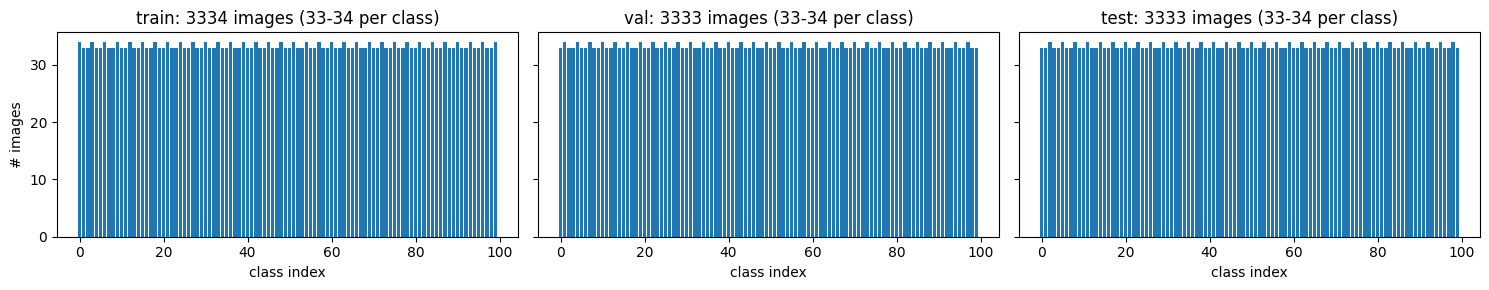

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
for a, s in zip(ax, ["train", "val", "test"]):
    cnt = Counter(caches[s]["labels"])
    counts = [cnt[i] for i in range(num_classes)]
    a.bar(range(num_classes), counts)
    a.set_title(f"{s}: {len(caches[s]['labels'])} images ({min(counts)}-{max(counts)} per class)")
    a.set_xlabel("class index")
ax[0].set_ylabel("# images")
plt.tight_layout()
plt.show()

In [7]:
# Data-leakage check: the three splits must not share any image
files = {s: set(FGVCAircraft(DATA_ROOT, split=s, annotation_level="variant")._image_files) for s in ["train", "val", "test"]}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a} ∩ {b}: {len(files[a] & files[b])} shared images")

train ∩ val: 0 shared images
train ∩ test: 0 shared images
val ∩ test: 0 shared images


> *Observations:* the dataset is perfectly balanced (33–34 images per class in every split), so plain accuracy is a fair metric and no class re-weighting is needed. With only ≈33 training images per class, overfitting is the main risk: regularization and data augmentation will be essential.

#### 1.3.2 Image size and aspect ratio

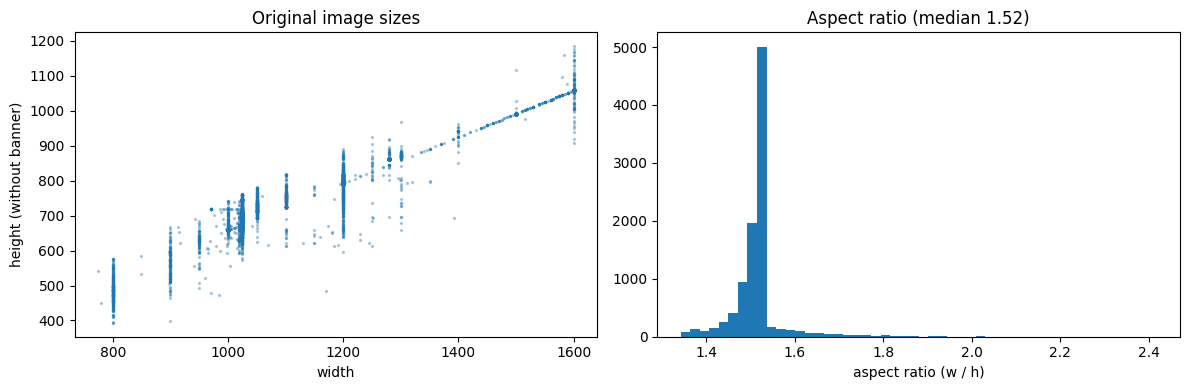

In [8]:
sizes = np.array([s for c in caches.values() for s in c["orig_sizes"]])
w, h = sizes[:, 0], sizes[:, 1] - BANNER_PX
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(w, h, s=2, alpha=0.3)
ax[0].set_xlabel("width"); ax[0].set_ylabel("height (without banner)"); ax[0].set_title("Original image sizes")
ax[1].hist(w / h, bins=50)
ax[1].set_xlabel("aspect ratio (w / h)"); ax[1].set_title(f"Aspect ratio (median {np.median(w / h):.2f})")
plt.tight_layout()
plt.show()

> *Observations:* original images are large (800–1600 px wide), so downsampling to ≈224 px discards fine details. The aspect ratio is tightly concentrated around 1.5 (median 1.52): a square center crop keeps only ≈66% of the width and can cut the nose and tail of the aircraft (see 1.4), which motivates comparing different ways of obtaining the network input.

#### 1.3.3 Copyright banner

The bottom of each original image contains a copyright banner, which carries no information about the aircraft.
The red line marks the crop applied in the cache (`BANNER_PX` pixels from the bottom).

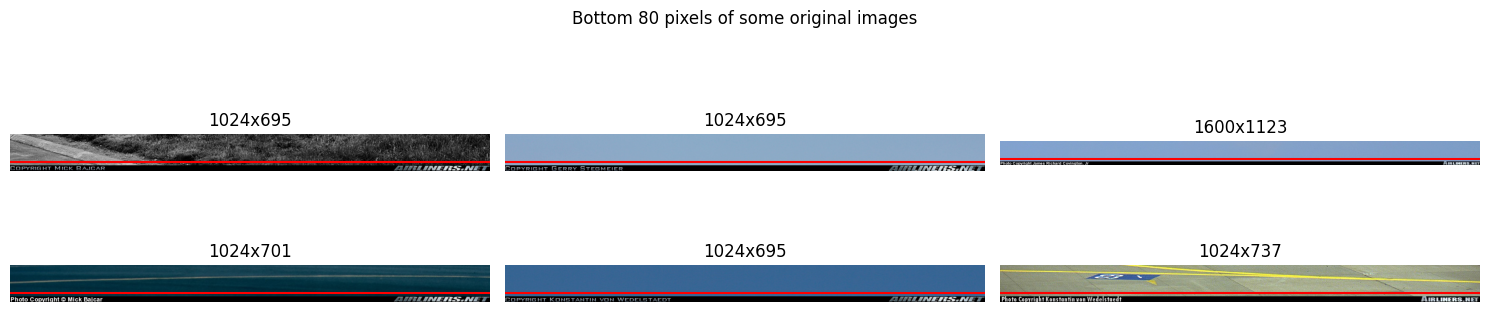

In [9]:
raw = FGVCAircraft(DATA_ROOT, split="train", annotation_level="variant")
idxs = np.linspace(0, len(raw) - 1, 6).astype(int)
fig, ax = plt.subplots(2, 3, figsize=(15, 4))
for a, i in zip(ax.flat, idxs):
    img = np.array(raw[i][0])
    a.imshow(img[-80:])
    a.axhline(80 - BANNER_PX, color="red")
    a.set_title(f"{img.shape[1]}x{img.shape[0]}"); a.axis("off")
plt.suptitle("Bottom 80 pixels of some original images")
plt.tight_layout()
plt.show()

#### 1.3.4 Examples

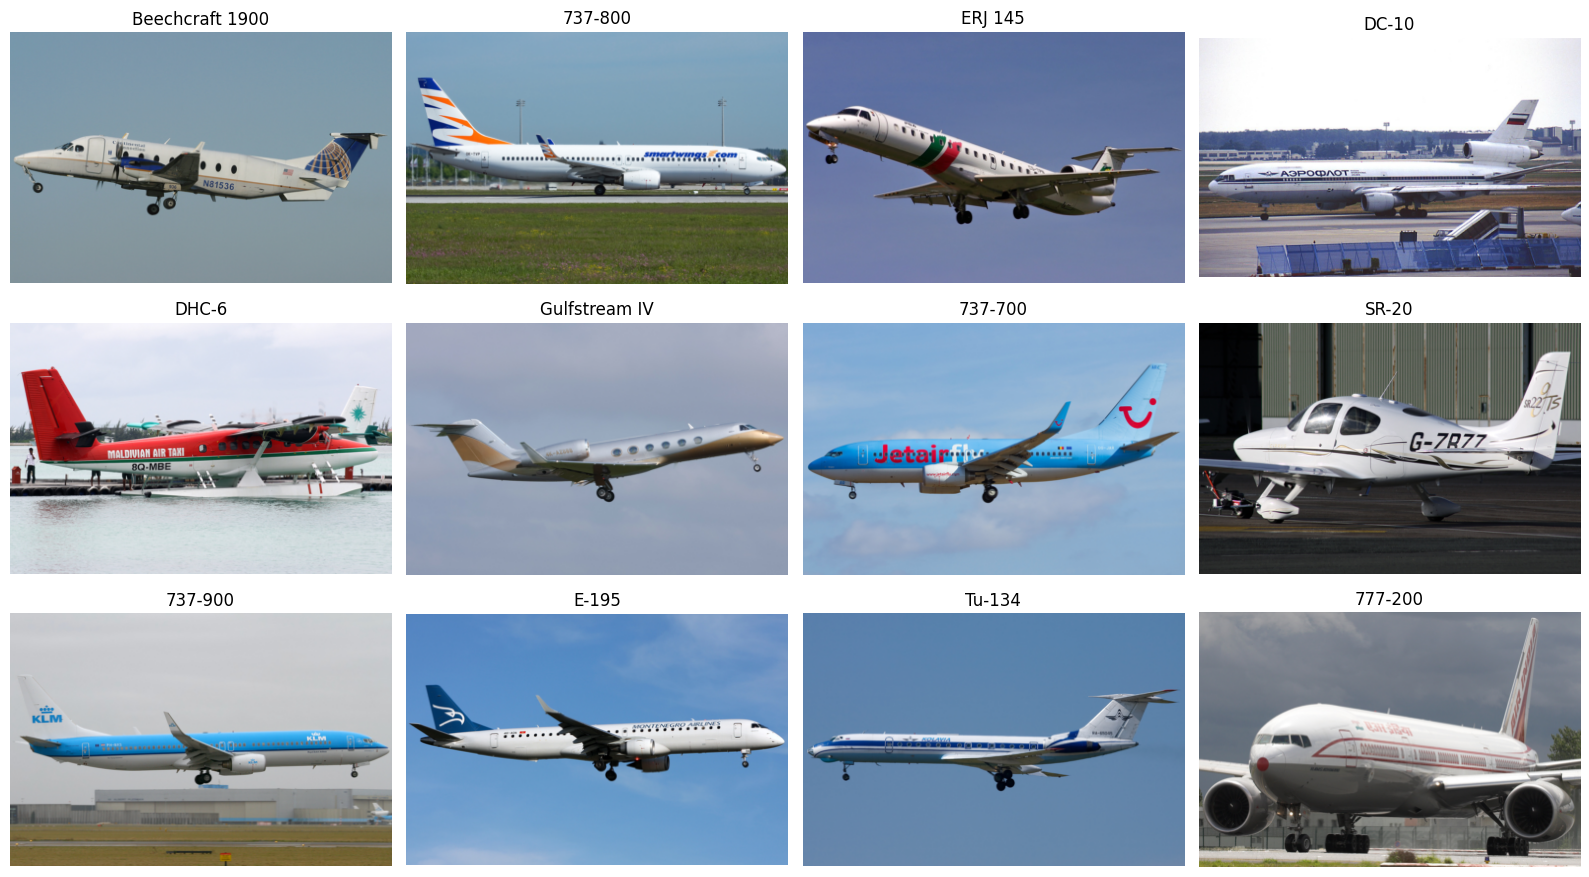

In [10]:
rng = np.random.default_rng(SEED)
train_labels = np.array(caches["train"]["labels"])
fig, ax = plt.subplots(3, 4, figsize=(16, 9))
for a, c in zip(ax.flat, rng.choice(num_classes, 12, replace=False)):
    i = rng.choice(np.where(train_labels == c)[0])
    a.imshow(caches["train"]["images"][i].permute(1, 2, 0))
    a.set_title(classes[c]); a.axis("off")
plt.tight_layout()
plt.show()

Variants of the same family (here: Boeing 737) differ only in small details — this is what makes the task *fine-grained*.

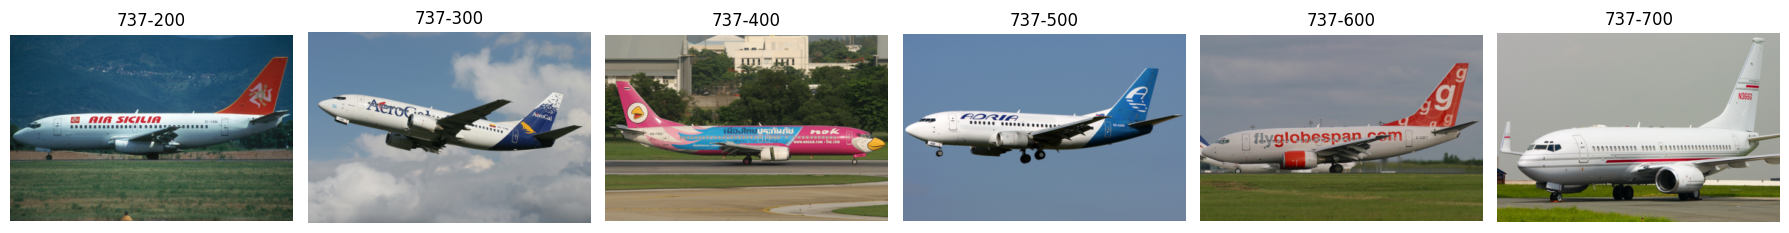

In [11]:
family = [i for i, c in enumerate(classes) if c.startswith("737")][:6]
fig, ax = plt.subplots(1, len(family), figsize=(3 * len(family), 3), squeeze=False)
for a, c in zip(ax[0], family):
    i = np.where(train_labels == c)[0][0]
    a.imshow(caches["train"]["images"][i].permute(1, 2, 0))
    a.set_title(classes[c]); a.axis("off")
plt.tight_layout()
plt.show()

> *Observations:* aircraft are mostly seen from the side, centered and covering most of the image width. Variants of the same family (e.g. 737-200 … 737-700) are nearly identical, differing mainly in fuselage length and small details, so most errors are expected within families. The airline livery is a potential shortcut, since the same airline operates several variants and the same variant appears with many liveries. Some photos are grayscale, which supports the use of color augmentations.

### 1.4 Preprocessing, augmentation and data loaders

Images are normalized with the ImageNet statistics in every part of the assignment, so that the pretrained ResNet-18 of Part 2
receives inputs in the distribution it was trained on, and Part 2A can truly reuse the pipeline of Part 1 unchanged.

Since images are ≈1.5 times wider than tall (Section 1.3.2), we compare three ways of obtaining the network input
(`resize_mode`):
- `"crop"`: resize the short side, then take a central square crop — may cut the nose and the tail of the aircraft;
- `"squash"`: resize the whole image to a square — keeps the whole aircraft, but compresses it horizontally;
- `"rect"`: resize the whole image to a rectangle with aspect ratio 1.5 (e.g. 192×288) — keeps the whole aircraft with almost
  no distortion, at a cost similar to 224×224 (55k vs 50k pixels). This works because networks ending with a global average
  pooling accept inputs of any spatial size.

At training time, `RandomResizedCrop` samples crops whose aspect ratio is centered on the one of the evaluation geometry,
so that aircraft have the same shape at training and test time (1 for `"crop"`, 1.5 for `"squash"` and `"rect"`).
The `"strong"` augmentation adds color jitter and random grayscale conversion, motivated by the livery shortcut and by the
presence of grayscale photos.

In [12]:
from torchvision.io import ImageReadMode, decode_jpeg

IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def input_hw(cfg: dict):
    """(H, W) of the network input: img_size is an int (square) or [H, W] (rect)."""
    size = cfg.get("img_size", 224)
    return (size, size) if isinstance(size, int) else tuple(size)


def make_transforms(train: bool, cfg: dict):
    """cfg keys (defaults):
       img_size (224) | resize_mode ("crop" | "squash" | "rect") | aug ("none" | "basic" | "strong") | rrc_scale ((0.35, 1))
    """
    mode, aug = cfg.get("resize_mode", "crop"), cfg.get("aug", "basic")
    h, w = input_hw(cfg)
    if mode == "crop":
        assert h == w, "crop mode needs a square img_size"
        ops, ar = [v2.Resize(int(round(h * 256 / 224)), antialias=True), v2.CenterCrop(h)], 1.0
    elif mode == "squash":
        assert h == w, "squash mode needs a square img_size"
        ops, ar = [v2.Resize((h, w), antialias=True)], DATA_ASPECT
    elif mode == "rect":
        ops, ar = [v2.Resize((h, w), antialias=True)], w / h
    else:
        raise ValueError(mode)
    if train and aug != "none":
        ops = [v2.RandomResizedCrop((h, w), scale=tuple(cfg.get("rrc_scale", (0.35, 1.0))),
                                    ratio=(ar * 3 / 4, ar * 4 / 3), antialias=True),
               v2.RandomHorizontalFlip()]
        if aug == "strong":
            ops += [v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3), v2.RandomGrayscale(p=0.1)]
        elif aug != "basic":
            raise ValueError(aug)
    return v2.Compose(ops + [v2.ToDtype(torch.float32, scale=True), v2.Normalize(IMAGENET_MEAN, IMAGENET_STD)])


class CachedDataset(Dataset):
    def __init__(self, cache: dict, transform=None):
        self.images, self.labels, self.transform = cache["images"], cache["labels"], transform
        self.jpeg = cache.get("format", "raw") == "jpeg"

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        x = self.images[i]
        if self.jpeg:
            x = decode_jpeg(x, mode=ImageReadMode.RGB)
        return (self.transform(x) if self.transform else x), self.labels[i]


MAX_WORKERS = 8  # every worker is a separate process with its own memory


def make_loader(split: str, cfg: dict, train: bool, batch_size=None, seed=SEED):
    """Loader of a split, built on the cache at the resolution cfg["short_side"] (default SHORT_SIDE)."""
    short_side = cfg.get("short_side", SHORT_SIDE)
    h, w = input_hw(cfg)
    needed = int(round(h * 256 / 224)) if cfg.get("resize_mode", "crop") == "crop" else h
    if needed > short_side:  # never upsample the cached images silently
        raise ValueError(f"a {h}x{w} input ({cfg.get('resize_mode', 'crop')}) needs images with short side >= {needed}, "
                         f"but the cache has {short_side}: set short_side in the config")
    ds = CachedDataset(get_cache(split, short_side), make_transforms(train, cfg))
    g = torch.Generator(); g.manual_seed(seed)
    nw = min(os.cpu_count(), MAX_WORKERS)
    return DataLoader(ds, batch_size=batch_size or cfg.get("batch_size", 64), shuffle=train, drop_last=train,
                      num_workers=nw, pin_memory=torch.cuda.is_available(), persistent_workers=nw > 0,
                      generator=g if train else None)


def denormalize(x: torch.Tensor) -> torch.Tensor:
    mean = torch.tensor(IMAGENET_MEAN).view(-1, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(-1, 1, 1)
    return (x.cpu() * std + mean).clamp(0, 1)

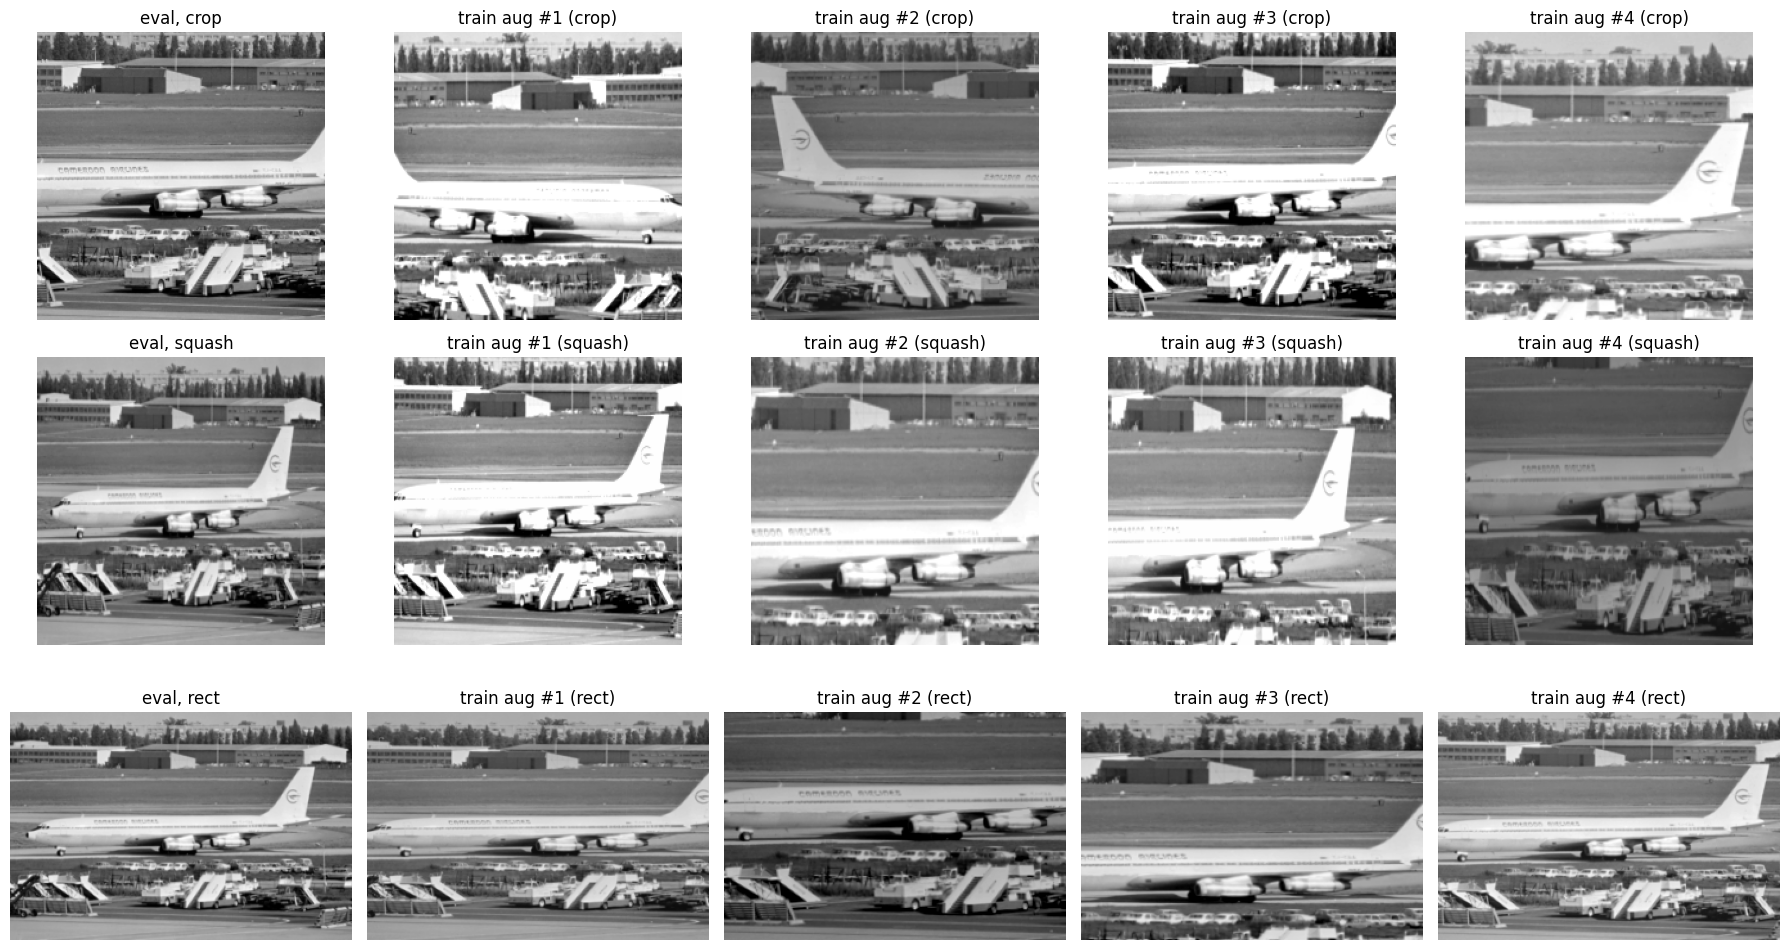

In [13]:
img = caches["train"]["images"][7]
geometries = {"crop": {"resize_mode": "crop", "img_size": 224},
              "squash": {"resize_mode": "squash", "img_size": 224},
              "rect": {"resize_mode": "rect", "img_size": [192, 288]}}
fig, ax = plt.subplots(len(geometries), 5, figsize=(18, 3.3 * len(geometries)))
for row, (name, g) in zip(ax, geometries.items()):
    row[0].imshow(denormalize(make_transforms(False, g)(img)).permute(1, 2, 0)); row[0].set_title(f"eval, {name}")
    t_aug = make_transforms(True, dict(g, aug="strong"))
    for k, a in enumerate(row[1:]):
        a.imshow(denormalize(t_aug(img)).permute(1, 2, 0)); a.set_title(f"train aug #{k + 1} ({name})")
    for a in row:
        a.axis("off")
plt.tight_layout()
plt.show()

> *Observations:* the center crop cuts the nose of the aircraft, squashing keeps it at the cost of a horizontal compression, while the rectangular input keeps the whole aircraft essentially undistorted. Too small random crops keep only a portion of the fuselage and lose discriminative parts, so the lower bound of the crop scale (`rrc_scale`) is treated as a hyperparameter.

## 2. Training utilities

Shared by all parts of the assignment:
- **2.1** optimizer, learning rate schedules (step, cosine with warm-up, one-cycle — L6), MixUp / CutMix;
- **2.2** training loop with mixed precision, model selection on the **validation** split only, checkpoints and history saved
  at every epoch, automatic resume after a disconnection;
- **2.3** `run_experiment`: runs an experiment only if it has not been completed yet — neither locally nor among the published
  runs — otherwise it just loads its results, so the notebook can be executed top to bottom without retraining anything; the
  test split is evaluated once, on the best-validation checkpoint, at the end of each run. Optional live logging to W&B;
- **2.4** plots and tables built from the saved runs (local and published);
- **2.5** downloading and publishing the runs with `gdown`.

### 2.1 Optimizers, schedules and batch mixing

In [14]:
def build_optimizer(params, cfg: dict):
    """`params` is either model.parameters() or a list of parameter groups (e.g. different LRs in Part 2B)."""
    name, lr, wd = cfg.get("optimizer", "sgd"), cfg["lr"], cfg.get("wd", 0.0)
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=cfg.get("momentum", 0.9), nesterov=True, weight_decay=wd)
    if name == "adamw":
        return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    raise ValueError(name)


def build_scheduler(optimizer, cfg: dict, steps_per_epoch: int):
    """All schedules are updated at every step (mini-batch)."""
    name = cfg.get("scheduler", "cosine")
    total = cfg["epochs"] * steps_per_epoch
    warmup = cfg.get("warmup_epochs", 0) * steps_per_epoch
    if name == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[g["lr"] for g in optimizer.param_groups],
                                                   total_steps=total)
    if name == "cosine":
        def f(step):
            if step < warmup:
                return (step + 1) / warmup
            return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total - warmup)))
    elif name == "step":
        milestones = [m * steps_per_epoch for m in cfg.get("milestones", [])]

        def f(step):
            if step < warmup:
                return (step + 1) / warmup
            return cfg.get("gamma", 0.1) ** sum(step >= m for m in milestones)
    elif name == "constant":
        def f(step):
            return 1.0
    else:
        raise ValueError(name)
    return torch.optim.lr_scheduler.LambdaLR(optimizer, f)


def build_batch_mix(cfg: dict):
    """MixUp / CutMix on whole batches (L6). Returns None if both are disabled."""
    ops = []
    if cfg.get("mixup_alpha", 0) > 0:
        ops.append(v2.MixUp(alpha=cfg["mixup_alpha"], num_classes=num_classes))
    if cfg.get("cutmix_alpha", 0) > 0:
        ops.append(v2.CutMix(alpha=cfg["cutmix_alpha"], num_classes=num_classes))
    if not ops:
        return None
    return ops[0] if len(ops) == 1 else v2.RandomChoice(ops)

### 2.2 Training loop

The validation loss is always the plain cross-entropy (without label smoothing), so that it is comparable across runs.

In [15]:
def save_json(obj, path):
    tmp = f"{path}.tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)


def load_json(path):
    with open(path) as f:
        return json.load(f)


@torch.no_grad()
def evaluate(model, loader, return_preds=False):
    model.eval()
    use_amp = device.type == "cuda"
    tot_loss, correct, n, preds, labels = 0.0, 0, 0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            out = model(x)
        tot_loss += F.cross_entropy(out.float(), y, reduction="sum").item()
        p = out.argmax(1)
        correct += (p == y).sum().item()
        n += y.numel()
        if return_preds:
            preds.append(p.cpu()); labels.append(y.cpu())
    res = {"loss": tot_loss / n, "acc": correct / n}
    if return_preds:
        res["preds"], res["labels"] = torch.cat(preds), torch.cat(labels)
    return res


def train_model(model, train_loader, val_loader, cfg, run_dir, params=None, log_fn=None):
    """Trains `model` and writes in `run_dir`: history.json (every epoch), best.pt (best validation accuracy),
    last.pt (full state, to resume after a disconnection). log_fn(dict) is called at the end of every epoch (e.g. W&B)."""
    use_amp = cfg.get("amp", True) and device.type == "cuda"
    optimizer = build_optimizer(model.parameters() if params is None else params, cfg)
    scheduler = build_scheduler(optimizer, cfg, len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg.get("label_smoothing", 0.0))
    batch_mix = build_batch_mix(cfg)

    history = {k: [] for k in ["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "lr", "epoch_time"]}
    start_epoch, best_acc, best_epoch = 0, -1.0, -1
    last_path = f"{run_dir}/last.pt"
    if os.path.exists(last_path):
        ckpt = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model"]); optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"]); scaler.load_state_dict(ckpt["scaler"])
        history, best_acc, best_epoch, start_epoch = ckpt["history"], ckpt["best_acc"], ckpt["best_epoch"], ckpt["epoch"] + 1
        print(f"Resuming from epoch {start_epoch} (best val acc so far {best_acc:.4f} at epoch {best_epoch})")

    pbar = tqdm(range(start_epoch, cfg["epochs"]), desc=os.path.basename(run_dir), initial=start_epoch, total=cfg["epochs"])
    for epoch in pbar:
        t0 = time.time()
        model.train()
        tot_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            y_hard = y
            if batch_mix is not None:
                x, y = batch_mix(x, y)  # y becomes a soft label
                y_hard = y.argmax(1)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if cfg.get("grad_clip", 0) > 0:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            tot_loss += loss.item() * y_hard.numel()
            correct += (out.argmax(1) == y_hard).sum().item()
            n += y_hard.numel()

        val = evaluate(model, val_loader)
        for k, v in [("epoch", epoch), ("train_loss", tot_loss / n), ("train_acc", correct / n), ("val_loss", val["loss"]),
                     ("val_acc", val["acc"]), ("lr", optimizer.param_groups[0]["lr"]), ("epoch_time", time.time() - t0)]:
            history[k].append(v)
        if val["acc"] > best_acc:
            best_acc, best_epoch = val["acc"], epoch
            torch.save(model.state_dict(), f"{run_dir}/best.pt")
        save_json(history, f"{run_dir}/history.json")
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                    "scaler": scaler.state_dict(), "history": history, "best_acc": best_acc, "best_epoch": best_epoch,
                    "epoch": epoch}, last_path)
        if log_fn is not None:
            log_fn({k: v[-1] for k, v in history.items()})
        pbar.set_postfix(train_acc=f"{correct / n:.3f}", val_acc=f"{val['acc']:.3f}", best=f"{best_acc:.3f}")
    return history, best_acc, best_epoch

### 2.3 Running an experiment

`run_experiment(name, build_model, cfg)` saves everything in `RUNS_DIR/<AUTHOR>_<name>/`. Runs are always referred to by
their name only, whoever trained them: the author is just a piece of information stored with the run, so run names must be
unique within the team. If the run has already been completed — by you, or by another team member who published it — it
only loads its results; if it was interrupted it resumes it. If a run
with the same name exists but with a *different* configuration, it stops with an error, so that results are never silently
mixed up: change the name instead.

With `ALLOW_TRAINING = False` a run that is not available is skipped (`run_experiment` returns `None`) instead of trained.

With `USE_WANDB`, every trained run is also logged to W&B. The W&B run id is stored in the run folder, so a run resumed after
a disconnection continues the same W&B run instead of creating a new one.

In [16]:
def run_dir_of(name):
    """Folder where you train the run `name`."""
    return f"{RUNS_DIR}/{AUTHOR}_{name}"


def find_run_dir(name, required="config.json"):
    """Folder of the run `name` (without author) containing the file `required`, or None if there is none.
    Your runs come first (local, then published), then the published runs of the other team members."""
    found = []
    for base in (RUNS_DIR, PUBLISHED_DIR):
        for folder in os.listdir(base):
            author, _, short = folder.partition("_")
            if short == name and os.path.exists(f"{base}/{folder}/{required}"):
                found.append((author != AUTHOR, base != RUNS_DIR, author, f"{base}/{folder}"))
    if not found:
        return None
    found.sort()
    if found[0][2] != AUTHOR and len({f[2] for f in found}) > 1:
        raise ValueError(f"run '{name}' exists for several authors {sorted({f[2] for f in found})}: rename one of them")
    return found[0][3]


def is_done(name):
    return find_run_dir(name, "results.json") is not None


def wandb_start(full_name, cfg, run_dir):
    """Starts the W&B run of a run folder, or resumes it if the folder already has one (e.g. after a disconnection)."""
    id_path = f"{run_dir}/wandb_id.txt"
    if os.path.exists(id_path):
        with open(id_path) as f:
            run_id = f.read().strip()
    else:
        run_id = uuid.uuid4().hex[:12]
        with open(id_path, "w") as f:
            f.write(run_id)
    run = wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name=full_name, id=run_id, resume="allow", config=cfg)
    run.define_metric("epoch")
    for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr", "epoch_time"]:
        run.define_metric(k, step_metric="epoch", summary="max" if k == "val_acc" else "last")
    return run


def run_experiment(name, build_model, cfg, build_params=None, force=False, log_wandb=True):
    """build_model(cfg) -> nn.Module; build_params(model, cfg) -> parameter groups (optional).
    force=True re-trains the run from scratch, even if it is already completed (by you or by another team member)."""
    assert "_" not in AUTHOR, "AUTHOR must not contain '_'"
    run_dir = run_dir_of(name)
    cfg = json.loads(json.dumps(cfg))  # normalize (tuples -> lists) to compare it with the saved one
    force = force and ALLOW_TRAINING  # in read-only mode existing results are always loaded
    existing = None if force else find_run_dir(name)
    if existing:
        saved = {k: v for k, v in load_json(f"{existing}/config.json").items() if k in cfg}
        if saved != cfg:
            raise ValueError(f"'{name}' already exists in {existing} with a different config: "
                             "use another name (or force=True to re-train it).")
        if os.path.exists(f"{existing}/results.json"):
            res = load_json(f"{existing}/results.json")
            where = "local" if existing.startswith(RUNS_DIR) else f"published by {os.path.basename(existing).partition('_')[0]}"
            print(f"[{name}] already completed ({where}): val acc {res['best_val_acc']:.4f} | test acc {res['test_acc']:.4f}")
            return res
    if not ALLOW_TRAINING:
        print(f"[{name}] not available and ALLOW_TRAINING = False: skipped")
        return None
    if force and os.path.exists(run_dir):
        shutil.rmtree(run_dir)  # start from scratch: never resume a checkpoint of a different config

    os.makedirs(run_dir, exist_ok=True)
    fix_random(cfg.get("seed", SEED))
    model = build_model(cfg).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    meta = dict(cfg, author=AUTHOR, gpu=GPU_NAME, n_params=n_params, n_trainable=n_trainable)
    save_json(meta, f"{run_dir}/config.json")
    print(f"[{name}] {n_params / 1e6:.2f}M parameters ({n_trainable / 1e6:.2f}M trainable) on {GPU_NAME}")

    wb = wandb_start(f"{AUTHOR}_{name}", meta, run_dir) if (USE_WANDB and log_wandb) else None
    try:
        train_loader = make_loader("train", cfg, train=True, seed=cfg.get("seed", SEED))
        val_loader = make_loader("val", cfg, train=False, batch_size=128)
        params = build_params(model, cfg) if build_params else None
        history, best_acc, best_epoch = train_model(model, train_loader, val_loader, cfg, run_dir, params,
                                                    log_fn=wb.log if wb else None)

        # The test split is used only here, once, on the checkpoint selected on the validation split
        model.load_state_dict(torch.load(f"{run_dir}/best.pt", map_location=device))
        test_loader = make_loader("test", cfg, train=False, batch_size=128)
        test = evaluate(model, test_loader)
        res = {"best_epoch": best_epoch, "best_val_acc": best_acc, "test_acc": test["acc"], "test_loss": test["loss"],
               "train_acc_at_best": history["train_acc"][best_epoch], "n_params": n_params,
               "minutes": sum(history["epoch_time"]) / 60}
        save_json(res, f"{run_dir}/results.json")
    except BaseException:
        if wb:
            wb.finish(exit_code=1)  # shown as failed on W&B; the next call resumes the same W&B run
        raise
    finally:
        # shut down the worker processes of the loaders (persistent workers would otherwise outlive the run)
        train_loader = val_loader = test_loader = None
        gc.collect()
    if wb:
        wb.summary.update({f"final/{k}": v for k, v in res.items()})
        wb.finish()
    print(f"[{name}] best epoch {best_epoch} | val acc {best_acc:.4f} | test acc {test['acc']:.4f}")
    return res


def load_trained_model(name, build_model):
    run_dir = find_run_dir(name, "best.pt")
    if run_dir is None:
        raise FileNotFoundError(f"no checkpoint for run '{name}' (was it published with its checkpoint?)")
    cfg = load_json(f"{run_dir}/config.json")
    model = build_model(cfg).to(device)
    model.load_state_dict(torch.load(f"{run_dir}/best.pt", map_location=device))
    return model.eval(), cfg

### 2.4 Plots and tables from saved runs

In [17]:
import pandas as pd


def list_runs():
    """All the saved runs (yours and the published ones): {name: folder}."""
    runs = {}
    for base in (RUNS_DIR, PUBLISHED_DIR):
        for folder in sorted(os.listdir(base)):
            name = folder.partition("_")[2]
            if os.path.exists(f"{base}/{folder}/history.json"):
                runs.setdefault(name, f"{base}/{folder}")
    return runs


def _load(name):
    d = find_run_dir(name)
    if d is None:
        raise FileNotFoundError(f"run '{name}' not found")
    res = load_json(f"{d}/results.json") if os.path.exists(f"{d}/results.json") else {}
    return load_json(f"{d}/config.json"), load_json(f"{d}/history.json"), res


def _available(names, labels=None):
    """Keeps the runs that exist (even if still in progress) and reports the missing ones."""
    labels = labels or names
    exists = lambda n: find_run_dir(n, "history.json") is not None
    missing = [n for n in names if not exists(n)]
    if missing:
        print(f"Not available, skipped: {missing}")
    keep = [(n, l) for n, l in zip(names, labels) if exists(n)]
    return [n for n, _ in keep], [l for _, l in keep]


def plot_runs(names, labels=None, title=None):
    """Loss, accuracy (dashed = train, solid = validation) and learning rate of some runs."""
    names, labels = _available(names, labels)
    if not names:
        return
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    for name, label in zip(names, labels):
        _, h, _ = _load(name)
        line, = ax[0].plot(h["epoch"], h["val_loss"], label=label)
        c = line.get_color()
        ax[0].plot(h["epoch"], h["train_loss"], "--", color=c, alpha=0.6)
        ax[1].plot(h["epoch"], h["val_acc"], color=c, label=label)
        ax[1].plot(h["epoch"], h["train_acc"], "--", color=c, alpha=0.6)
        ax[2].plot(h["epoch"], h["lr"], color=c, label=label)
    ax[0].set_title("loss"); ax[1].set_title("accuracy"); ax[2].set_title("learning rate")
    for a in ax:
        a.set_xlabel("epoch"); a.grid(alpha=0.3)
    ax[1].legend(fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def results_table(names, labels=None, reference=None):
    """One row per run; `reference` (a run name) adds the differences in accuracy w.r.t. that run."""
    names, labels = _available(names, labels)
    if not names:
        return pd.DataFrame()
    rows = []
    for name, label in zip(names, labels):
        cfg, h, res = _load(name)
        rows.append({"run": label, "params (M)": cfg.get("n_params", float("nan")) / 1e6,
                     "epochs": len(h["epoch"]), "best epoch": res.get("best_epoch"),
                     "train acc @best": res.get("train_acc_at_best"), "val acc": res.get("best_val_acc"),
                     "test acc": res.get("test_acc"), "minutes": res.get("minutes"), "gpu": cfg.get("gpu")})
    df = pd.DataFrame(rows).set_index("run")
    if reference is not None and is_done(reference):  # decisions are taken on the validation accuracy; Δ test is only reported
        ref = _load(reference)[2]
        df["Δ val acc"] = df["val acc"] - ref.get("best_val_acc")
        df["Δ test acc"] = df["test acc"] - ref.get("test_acc")
    return df.style.format(precision=3, na_rep="-")

### 2.5 Published runs

`publish_runs()` collects the completed runs of `RUNS_DIR` in a zip file: the json files of every run (configuration,
history, results) and the `best.pt` checkpoints of the runs that are needed later (e.g. for the error analysis of the final
models). The zip is written in `STORE_DIR`; once shared on Drive as *anyone with the link*, its file ID goes in
`PUBLISHED_RUNS` and `fetch_published_runs()` downloads and extracts it in `PUBLISHED_DIR` with `gdown`.
Publishing again overwrites the same file on Drive, so the ID, and therefore the notebook, does not change (it is worth
checking once; otherwise upload the new zip with *Manage versions*, which always keeps the ID).

`wandb_backfill()` logs to W&B the completed local runs that were trained without it.

In [18]:
RUN_FILES = ["config.json", "history.json", "results.json"]


def publish_runs(zip_name=f"runs_{AUTHOR}.zip", prefix=f"{AUTHOR}_", with_checkpoints=(), runs_dir=None):
    """Zips the completed runs of `runs_dir` (default: your RUNS_DIR) whose folder starts with `prefix`;
    `with_checkpoints` lists the run names whose best.pt is included too. The zip is written in your STORE_DIR.
    Example, publishing the runs of another team member from their Drive folder:
    publish_runs("runs_simone.zip", "simone_", ["p1_d2w2_reg_e100"], runs_dir="/content/drive/MyDrive/IPCV_A2_simone/runs")"""
    runs_dir = runs_dir or RUNS_DIR
    ckpt = {prefix + n for n in with_checkpoints}
    runs = [d for d in sorted(os.listdir(runs_dir)) if d.startswith(prefix) and os.path.exists(f"{runs_dir}/{d}/results.json")]
    missing = ckpt - set(runs)
    if missing:
        raise ValueError(f"not completed: {sorted(missing)}")
    tmp = f"/content/{zip_name}"
    with zipfile.ZipFile(tmp, "w", zipfile.ZIP_DEFLATED) as z:
        for r in runs:
            for f in RUN_FILES + (["best.pt"] if r in ckpt else []):
                z.write(f"{runs_dir}/{r}/{f}", f"{r}/{f}")
    shutil.copyfile(tmp, f"{STORE_DIR}/{zip_name}")  # overwrite in place: the Drive file keeps its ID
    print(f"{len(runs)} runs ({len(ckpt)} with checkpoint), {os.path.getsize(tmp) / 1e6:.1f} MB -> {STORE_DIR}/{zip_name}")


def fetch_published_runs(sources=None):
    """Downloads with gdown the zip files in `sources` ({label: Drive file ID}) and extracts them in PUBLISHED_DIR."""
    for label, file_id in (PUBLISHED_RUNS if sources is None else sources).items():
        zip_path = f"/content/published_{label}.zip"
        if gdown.download(f"https://drive.google.com/uc?id={file_id}", zip_path, quiet=True) is None:
            print(f"[{label}] download failed: is the file shared as 'anyone with the link'?")
            continue
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(PUBLISHED_DIR)
            n = len({p.split("/")[0] for p in z.namelist()})
        print(f"[{label}] {n} runs extracted in {PUBLISHED_DIR}")


def wandb_backfill(prefix=f"{AUTHOR}_"):
    """Logs to W&B the completed local runs that have no W&B run yet (e.g. trained before enabling W&B)."""
    for full_name in sorted(os.listdir(RUNS_DIR)):
        d = f"{RUNS_DIR}/{full_name}"
        if not full_name.startswith(prefix) or not os.path.exists(f"{d}/results.json") or os.path.exists(f"{d}/wandb_id.txt"):
            continue
        cfg, h, res = load_json(f"{d}/config.json"), load_json(f"{d}/history.json"), load_json(f"{d}/results.json")
        run = wandb_start(full_name, cfg, d)
        for i in range(len(h["epoch"])):
            run.log({k: v[i] for k, v in h.items()})
        run.summary.update({f"final/{k}": v for k, v in res.items()})
        run.finish()
        print(f"[{full_name}] logged to W&B")


fetch_published_runs()
if USE_WANDB:
    wandb_backfill()

### 2.6 Smoke test

A tiny network trained for 2 epochs on small images, only to check the whole chain (loaders, training, saving the run,
test evaluation, tables and plots). It runs on CPU as well; its folder is deleted at the end.

In [19]:
RUN_SMOKE_TEST = False

if RUN_SMOKE_TEST and ALLOW_TRAINING:
    def tiny_net(cfg):
        return nn.Sequential(nn.Conv2d(3, 16, 3, stride=2, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
                             nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(16, num_classes))

    smoke_cfg = {"img_size": [64, 96], "resize_mode": "rect", "aug": "strong", "batch_size": 64, "epochs": 2,
                 "optimizer": "sgd", "lr": 0.05, "wd": 5e-4, "scheduler": "cosine", "warmup_epochs": 1,
                 "label_smoothing": 0.1, "mixup_alpha": 0.2, "cutmix_alpha": 1.0}
    run_experiment("smoke_test", tiny_net, smoke_cfg, log_wandb=False)
    run_experiment("smoke_test", tiny_net, smoke_cfg, log_wandb=False)   # second call: must only load the results
    display(results_table(["smoke_test"]))
    plot_runs(["smoke_test"])
    shutil.rmtree(run_dir_of("smoke_test"))

## Part 1: design your own network

Your goal is to implement a convolutional neural network for image classification and train it from scratch on `FGVCAircraft`. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~50%. You are free to achieve this however you want, except for a few rules you must follow:

- Compile this notebook by displaying the results obtained by the best model you found throughout your experimentation; then show how, by removing some of its components, its performance drops. In other words, do an *ablation study* to prove that your design choices have a positive impact on the final result.

- Do not instantiate an off-the-self PyTorch network. Instead, construct your network as a composition of existing PyTorch layers. In more concrete terms, you can use e.g. `torch.nn.Linear`, but you cannot use e.g. `torchvision.models.alexnet`.

- Show your results and ablations with plots, tables, images, etc. — the clearer, the better.

Don't be too concerned with your model performance: the ~50% is just to give you an idea of when to stop. Keep in mind that a thoroughly justified model with lower accuracy will be rewarded more points than a poorly experimentally validated model with higher accuracy.

### P1.1 Network design

All the networks of Part 1 belong to one configurable family, `AircraftNet`, so that every ablation is obtained by changing
a single key of the configuration:

- **stem**: a 3×3 convolution with stride 2 that halves the resolution early (images are large, fine details are in the
  following layers);
- **4 stages** with increasing width (`widths`); the first block of every stage halves the resolution with stride 2, so the
  receptive field grows while the cost per stage stays similar. `depths` sets the number of blocks per stage;
- **blocks** (`block`): `"plain"` = two 3×3 conv–BN–ReLU; `"residual"` = the same two convolutions plus a skip connection
  (a 1×1 convolution when the shape changes), as in ResNet (L5);
- **batch normalization** after every convolution, which can be switched off (`bn`);
- **head**: global average pooling → dropout (`dropout`) → linear classifier. Global average pooling makes the network
  independent of the input size (needed for the rectangular input) and avoids a large, overfitting-prone fully connected layer.

Weights are initialized with the Kaiming (He) initialization, designed for ReLU networks (L4).

In [20]:
class Block(nn.Module):
    """Two 3x3 convolutions (+ BN + ReLU); with residual=True, a skip connection is added before the last ReLU."""

    def __init__(self, c_in, c_out, stride, residual, bn):
        super().__init__()
        self.residual = residual
        norm = (lambda c: nn.BatchNorm2d(c)) if bn else (lambda c: nn.Identity())
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=not bn)
        self.bn1 = norm(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=not bn)
        self.bn2 = norm(c_out)
        self.shortcut = None
        if residual and (stride != 1 or c_in != c_out):
            self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=stride, bias=not bn), norm(c_out))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + (x if self.shortcut is None else self.shortcut(x))
        return F.relu(out)


class AircraftNet(nn.Module):
    def __init__(self, num_classes, widths=(32, 64, 128, 256), depths=(1, 1, 1, 1), stem_width=32,
                 block="plain", bn=True, dropout=0.0):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, stem_width, 3, stride=2, padding=1, bias=not bn),
                                  nn.BatchNorm2d(stem_width) if bn else nn.Identity(), nn.ReLU(inplace=True))
        layers, c_in = [], stem_width
        for c_out, depth in zip(widths, depths):
            for i in range(depth):
                layers.append(Block(c_in, c_out, stride=2 if i == 0 else 1, residual=(block == "residual"), bn=bn))
                c_in = c_out
        self.stages = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))


def build_aircraftnet(cfg):
    return AircraftNet(num_classes, widths=tuple(cfg.get("widths", (32, 64, 128, 256))),
                       depths=tuple(cfg.get("depths", (1, 1, 1, 1))), stem_width=cfg.get("stem_width", 32),
                       block=cfg.get("block", "plain"), bn=cfg.get("bn", True), dropout=cfg.get("dropout", 0.0))

### P1.2 Baseline configuration and sanity checks

Following the recipe of L6 (slide 40), we start from a deliberately simple baseline — plain blocks, basic augmentation,
no label smoothing, no MixUp/CutMix, no dropout — and first verify that the pipeline is correct:
1. with random weights the network should predict an almost uniform distribution, so the initial loss should be close to
   $\ln(100) \approx 4.61$;
2. the network must be able to reach (almost) zero loss on a **single batch**: if it cannot, there is a bug in the data,
   the labels or the model.

parameters: 1.21M | input (32, 3, 192, 288) -> output (32, 100)
initial loss: 4.599 (expected ~4.605)


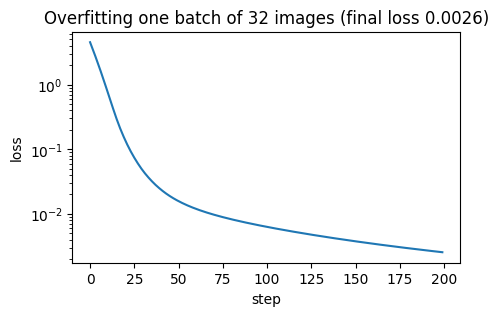

In [21]:
P1_BASE = {
    "seed": SEED,
    # input
    "img_size": [192, 288], "resize_mode": "rect", "aug": "basic", "rrc_scale": [0.35, 1.0],
    # model
    "widths": [32, 64, 128, 256], "depths": [1, 1, 1, 1], "stem_width": 32, "block": "plain", "bn": True, "dropout": 0.0,
    # training
    "batch_size": 64, "epochs": 40, "optimizer": "sgd", "lr": 0.05, "wd": 5e-4,
    "scheduler": "cosine", "warmup_epochs": 2, "label_smoothing": 0.0, "mixup_alpha": 0.0, "cutmix_alpha": 0.0,
}

fix_random(SEED)
model = build_aircraftnet(P1_BASE).to(device)
x, y = next(iter(make_loader("train", dict(P1_BASE, aug="none"), train=True, batch_size=32)))
x, y = x.to(device), y.to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M | input {tuple(x.shape)} -> output {tuple(model(x).shape)}")

# 1) initial loss
model.eval()
with torch.no_grad():
    print(f"initial loss: {F.cross_entropy(model(x), y).item():.3f} (expected ~{math.log(num_classes):.3f})")

# 2) overfit a single batch
model.train()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
losses = []
for step in range(200):
    loss = F.cross_entropy(model(x), y)
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
plt.figure(figsize=(5, 3))
plt.plot(losses); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("loss")
plt.title(f"Overfitting one batch of 32 images (final loss {losses[-1]:.4f})")
plt.show()
del model, opt

> *Observations:* the initial loss matches $\ln(100)$ and the network drives the loss on a single batch to ≈0.003 in 200 steps: data, labels and model are consistent, so the pipeline can be trusted.

### P1.3 Baseline

First real training run, which gives a first reference accuracy for the following experiments.

[p1_baseline] already completed (local): val acc 0.3453 | test acc 0.3453


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu
run,,,,,,,,
p1_baseline,1.208,40,38,0.652,0.345,0.345,9.884,Tesla T4


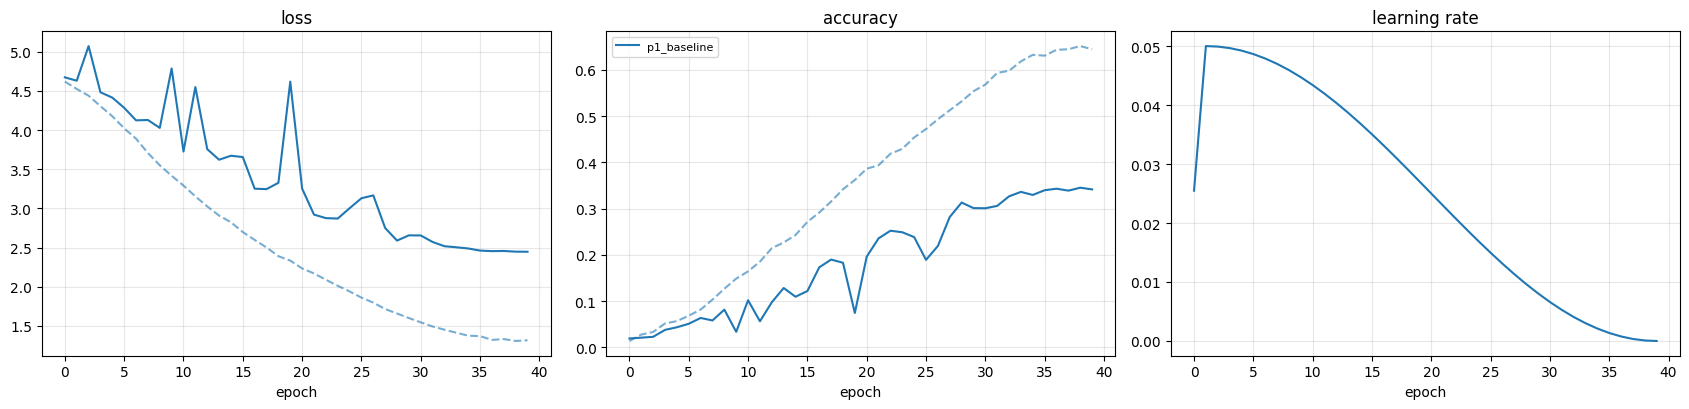

In [22]:
RUN_P1_BASELINE = True

if RUN_P1_BASELINE:
    run_experiment("p1_baseline", build_aircraftnet, P1_BASE)

name = "p1_baseline"
display(results_table([name]))
plot_runs([name])

> *Observations:* the baseline reaches 34.5% validation accuracy. Three issues emerge:
> 1. **large generalization gap**: 65% training vs 35% validation accuracy at the best epoch;
> 2. **limited capacity**: even on the training set (with augmentation) the network only reaches 65%, so it is not able to fit the data;
> 3. **instability at high learning rate**: while the LR is above ≈0.02, the validation loss shows large spikes (epochs 2, 9, 11, 19) although the training loss decreases smoothly; the curves become stable only when the cosine schedule lowers the LR.
>
> Following the recipe, we first increase the capacity of the network until it can fit the training set, then we regularize it.

### P1.4 Increasing the capacity

One change at a time with respect to the baseline, everything else fixed (same 40 epochs, same optimizer and schedule):
- `p1_res`: residual blocks instead of plain blocks — skip connections ease the optimization (L5) and may reduce the
  instability observed above;
- `p1_res_d2`: residual blocks, 2 blocks per stage (twice as deep);
- `p1_res_d2_w2`: residual, 2 blocks per stage, twice as wide (64 → 512 channels).

[p1_res] already completed (local): val acc 0.2643 | test acc 0.2703
[p1_res_d2] already completed (local): val acc 0.3921 | test acc 0.3780
[p1_res_d2_w2] already completed (local): val acc 0.3801 | test acc 0.3840


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
p1_baseline,1.208,40,38,0.652,0.345,0.345,9.884,Tesla T4,0.000,0.000
p1_res,1.253,40,36,0.623,0.264,0.270,9.217,Tesla T4,-0.081,-0.075
p1_res_d2,2.822,40,39,0.739,0.392,0.378,9.837,Tesla T4,0.047,0.033
p1_res_d2_w2,11.203,40,36,0.840,0.380,0.384,11.230,Tesla T4,0.035,0.039


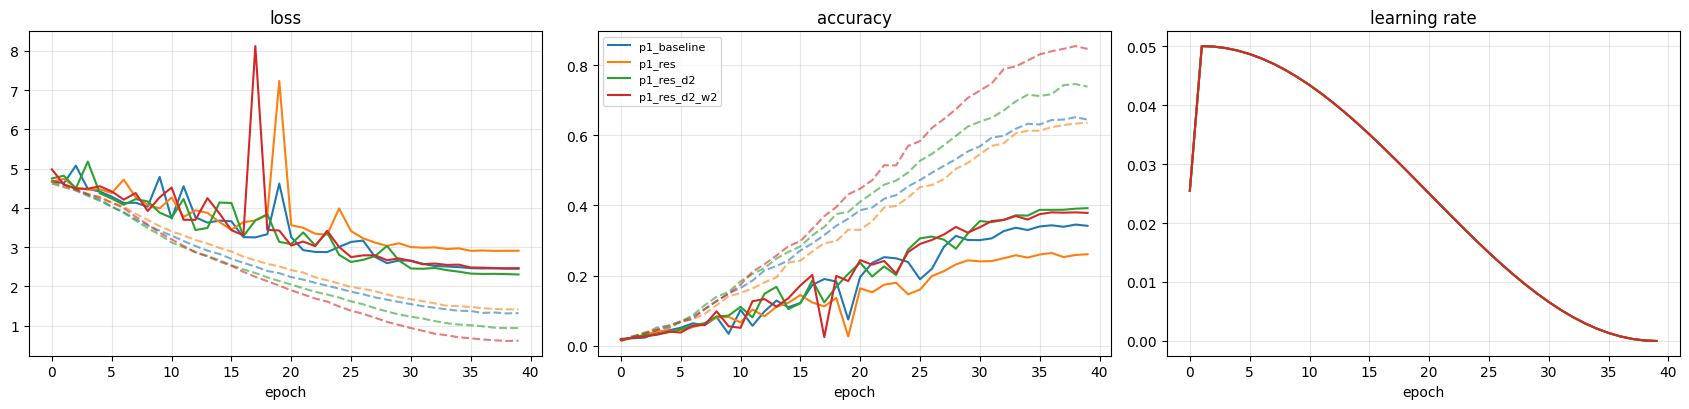

In [23]:
RUN_P1_CAPACITY = True

P1_CAPACITY = {
    "p1_res":       dict(P1_BASE, block="residual"),
    "p1_res_d2":    dict(P1_BASE, block="residual", depths=[2, 2, 2, 2]),
    "p1_res_d2_w2": dict(P1_BASE, block="residual", depths=[2, 2, 2, 2], widths=[64, 128, 256, 512]),
}
if RUN_P1_CAPACITY:
    for run_name, cfg in P1_CAPACITY.items():
        run_experiment(run_name, build_aircraftnet, cfg)

names = ["p1_baseline"] + list(P1_CAPACITY)
display(results_table(names, reference="p1_baseline"))
plot_runs(names)

> *Observations:* model selection is based on the validation accuracy (single seed, differences of 1–2 points are within noise).
> - **Residual blocks alone hurt** (`p1_res`, −8 points). With one block per stage, every block downsamples, so every skip connection is a strided 1×1 projection and never an identity: the network gets none of the benefits of residual learning, while the 1×1 stride-2 path only sees one pixel out of four. Skip connections pay off with deeper stages (`p1_res_d2`), where most shortcuts are identities.
> - **Depth helps**: `p1_res_d2` is the best model (39.2%), with training accuracy rising from 65% to 74%.
> - **Width increases the capacity but not the accuracy**: `p1_res_d2_w2` (11.2M parameters) fits the training set much better (84%), but validation accuracy does not improve (38.0%): capacity is no longer the bottleneck, and the generalization gap (46 points) is now the main problem.
> - **Instability persists in all models** while the LR is high (validation loss spikes up to 7–8), so the learning rate of 0.05 is likely too large; the curves become smooth only as the cosine schedule decays.
>
> Next step: regularization, on both the deeper and the wider network (the larger model may benefit more from it).

### P1.5 Regularization

The networks now have enough capacity; the goal is to reduce the generalization gap (L6). Regularizers are first added
together to see how far they can go — their individual contribution is measured later, in the ablation study:
- `aug="strong"`: color jitter and random grayscale on top of random crops and flips;
- `label_smoothing=0.1`: targets are 0.9 for the correct class instead of 1, which discourages over-confident predictions;
- `dropout=0.3` before the classifier.

The same recipe is applied to the deeper (`d2`) and the wider (`d2_w2`) network; a third run uses a smaller learning rate
(0.02), to check whether it removes the instability observed so far.

[p1_d2_reg] already completed (local): val acc 0.3192 | test acc 0.3144
[p1_d2w2_reg] already completed (local): val acc 0.3990 | test acc 0.3996
[p1_d2w2_reg_lr002] already completed (local): val acc 0.2880 | test acc 0.2763


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
p1_res_d2,2.822,40,39,0.739,0.392,0.378,9.837,Tesla T4,0.000,0.000
p1_res_d2_w2,11.203,40,36,0.840,0.380,0.384,11.230,Tesla T4,-0.012,0.006
p1_d2_reg,2.822,38,36,0.416,0.319,0.314,12.709,Tesla T4,-0.073,-0.064
p1_d2w2_reg,11.203,40,35,0.554,0.399,0.400,14.573,Tesla T4,0.007,0.022
p1_d2w2_reg_lr002,11.203,40,37,0.421,0.288,0.276,14.438,Tesla T4,-0.104,-0.102


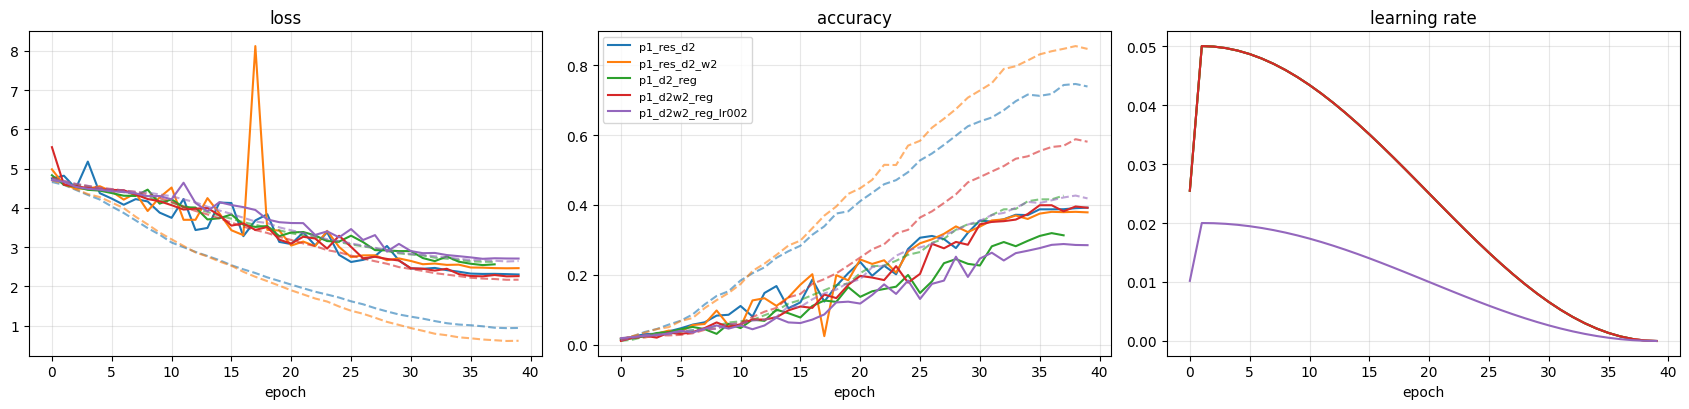

In [24]:
RUN_P1_REG = True

REG = {"aug": "strong", "label_smoothing": 0.1, "dropout": 0.3}
P1_REG = {
    "p1_d2_reg":         dict(P1_CAPACITY["p1_res_d2"], **REG),
    "p1_d2w2_reg":       dict(P1_CAPACITY["p1_res_d2_w2"], **REG),
    "p1_d2w2_reg_lr002": dict(P1_CAPACITY["p1_res_d2_w2"], **REG, lr=0.02),
}
if RUN_P1_REG:
    for run_name, cfg in P1_REG.items():
        run_experiment(run_name, build_aircraftnet, cfg)

names = ["p1_res_d2", "p1_res_d2_w2"] + list(P1_REG)
display(results_table(names, reference="p1_res_d2"))
plot_runs(names)

> *Observations:*
> - **Regularization pays off only with enough capacity.** On the wide network (`p1_d2w2_reg`, 11.2M) it gives the best model so far (39.9%) and shrinks the generalization gap from 46 to ≈18 points; on the smaller network (`p1_d2_reg`, 2.8M) it causes underfitting (training accuracy 42%) and lowers validation accuracy by 7 points.
> - **The instability disappears with regularization**: the wide regularized model has no validation-loss spikes even at LR 0.05. A plausible explanation is label smoothing, which prevents over-confident logits, so wrong predictions no longer produce huge losses.
> - **A smaller learning rate is not the solution**: with LR 0.02 the network learns more slowly and loses 11 points after 40 epochs.
> - **All regularized models are still improving at the end of training** (training accuracy < 60% and validation accuracy still rising), so 40 epochs are too few: the next step is a longer schedule.

### P1.6 Longer training and MixUp / CutMix

Regularized models learn more slowly, so we train for 100 epochs instead of 40:
- `p1_d2w2_reg_e100`: the best model so far, trained 2.5× longer;
- `p1_d2_reg_e100`: the smaller network, to check whether it catches up with a longer schedule;
- `p1_d2w2_reg_mix_e100`: the best model with MixUp (α = 0.2) or CutMix (α = 1), chosen at random for every batch (L6):
  a stronger regularizer that also discourages relying on a single region of the image (e.g. the livery on the tail).

[p1_d2w2_reg_e100] already completed (local): val acc 0.5902 | test acc 0.5836
[p1_d2_reg_e100] already completed (local): val acc 0.5653 | test acc 0.5734
[p1_d2w2_reg_mix_e100] already completed (local): val acc 0.5776 | test acc 0.5629


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
p1_d2w2_reg,11.203,40,35,0.554,0.399,0.400,14.573,Tesla T4,0.000,0.000
p1_d2w2_reg_e100,11.203,100,90,0.990,0.590,0.584,36.124,Tesla T4,0.191,0.184
p1_d2_reg_e100,2.822,100,93,0.934,0.565,0.573,32.709,Tesla T4,0.166,0.174
p1_d2w2_reg_mix_e100,11.203,100,92,0.706,0.578,0.563,36.070,Tesla T4,0.179,0.163


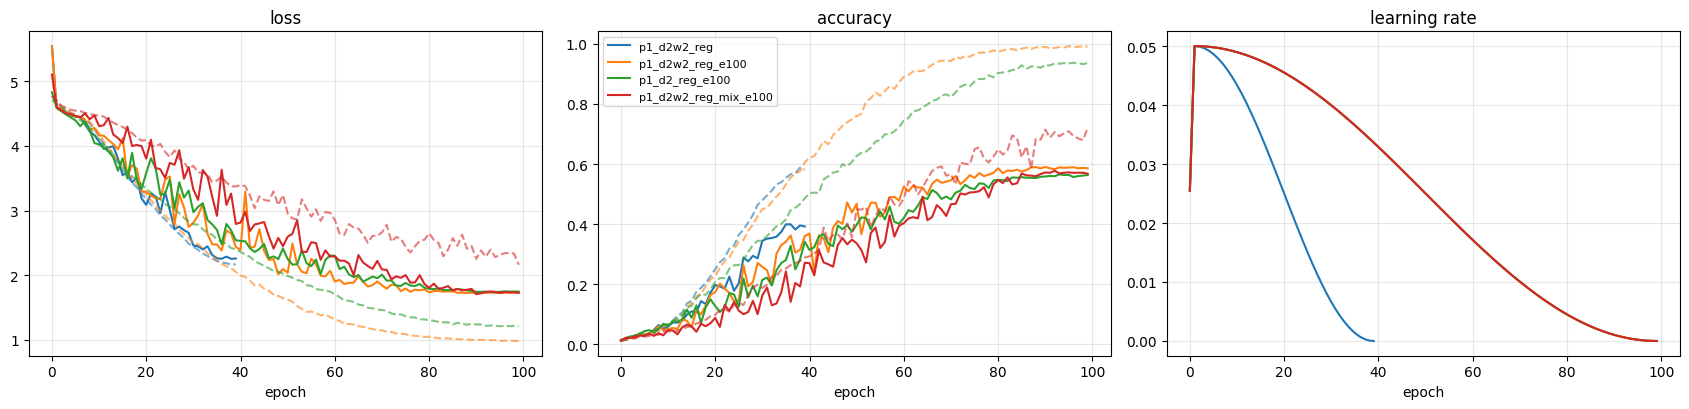

In [25]:
RUN_P1_LONG = True

P1_LONG = {
    "p1_d2w2_reg_e100":     dict(P1_REG["p1_d2w2_reg"], epochs=100),
    "p1_d2_reg_e100":       dict(P1_REG["p1_d2_reg"], epochs=100),
    "p1_d2w2_reg_mix_e100": dict(P1_REG["p1_d2w2_reg"], epochs=100, mixup_alpha=0.2, cutmix_alpha=1.0),
}
if RUN_P1_LONG:
    for run_name, cfg in P1_LONG.items():
        run_experiment(run_name, build_aircraftnet, cfg)

names = ["p1_d2w2_reg"] + list(P1_LONG)
display(results_table(names, reference="p1_d2w2_reg"))
plot_runs(names)

> *Observations:*
> - **Training longer is by far the most effective change**: with 100 epochs the wide regularized network reaches **59.0% validation / 58.4% test accuracy** (+19 points w.r.t. 40 epochs), above the 50% target. Its training accuracy reaches 99%, yet validation accuracy keeps improving until epoch ≈90: regularization lets the network fit the training set without memorizing it.
> - **The smaller network catches up** (56.5%, with 4× fewer parameters): the extra width is worth ≈2.5 points.
> - **MixUp / CutMix do not help within 100 epochs** (57.8%, −1.3 points, within noise): training accuracy stays at ≈70%, i.e. such a strong regularizer would need a longer schedule.
>
> We therefore fix `p1_d2w2_reg_e100` as the final model of Part 1.

### P1.7 First final model and ablation study

**First final model** (`p1_d2w2_reg_e100`): `AircraftNet` with residual blocks, 2 blocks per stage, widths 64–128–256–512
(11.2M parameters), batch normalization, dropout 0.3 before the classifier; rectangular 192×288 input with strong
augmentation; SGD with Nesterov momentum (LR 0.05, weight decay 5·10⁻⁴), cosine schedule with 2 warm-up epochs,
label smoothing 0.1, 100 epochs, batch size 64.

**Ablation study**: every run removes (or replaces) **one** component of the final model, everything else unchanged.
Some runs of the previous sections already differ from the final model in exactly one component and are reused.
A second run of the final model with a different seed estimates the run-to-run noise: differences smaller than that
should not be considered significant.

In [26]:
def ablation_report(final_name, ablation, reused, title="Ablation study"):
    """Table + bar chart of the Δ validation accuracy of every ablation w.r.t. the final model.
    ablation: {run name: (description, config)}; reused: {run name: description}. Only completed runs are shown."""
    done = is_done
    if not done(final_name):
        print(f"Final model '{final_name}' not available: ablation report skipped")
        return
    rows = [(final_name, "final model")] + [(n, d) for n, (d, _) in ablation.items() if done(n)] + \
           [(n, d) for n, d in reused.items() if done(n)]
    names, labels = [n for n, _ in rows], [d for _, d in rows]
    display(results_table(names, labels, reference=names[0]))
    ref = _load(names[0])[2]["best_val_acc"]
    deltas = [(_load(n)[2]["best_val_acc"] - ref) * 100 for n in names[1:]]
    order = np.argsort(deltas)
    plt.figure(figsize=(8, 0.45 * len(deltas) + 1))
    plt.barh([labels[1:][i] for i in order], [deltas[i] for i in order],
             color=["tab:red" if deltas[i] < 0 else "tab:green" for i in order])
    plt.axvline(0, color="black", lw=0.8)
    plt.xlabel("Δ validation accuracy w.r.t. the final model (points)")
    plt.title(title)
    plt.tight_layout()
    plt.show()


P1_FINAL_NAME = "p1_d2w2_reg_e100"
P1_FINAL = P1_LONG[P1_FINAL_NAME]

RUN_P1_ABLATION = True

P1_ABLATION = {  # run name: (description, config); ordered by expected informativeness
    "p1_abl_seed1":    ("final model, different seed",       dict(P1_FINAL, seed=SEED + 1)),
    "p1_abl_noaug":    ("no data augmentation",              dict(P1_FINAL, aug="none")),
    "p1_abl_plain":    ("plain blocks (no skip connections)", dict(P1_FINAL, block="plain")),
    "p1_abl_nobn":     ("no batch normalization",            dict(P1_FINAL, bn=False)),
    "p1_abl_nols":     ("no label smoothing",                dict(P1_FINAL, label_smoothing=0.0)),
    "p1_abl_nodrop":   ("no dropout",                        dict(P1_FINAL, dropout=0.0)),
    "p1_abl_crop":     ("square center crop, 224×224",       dict(P1_FINAL, resize_mode="crop", img_size=224)),
}
P1_REUSED = {  # runs of the previous sections that differ from the final model in one component only
    "p1_d2_reg_e100":       "half width (2.8M parameters)",
    "p1_d2w2_reg":          "40 epochs instead of 100",
    "p1_d2w2_reg_mix_e100": "+ MixUp / CutMix",
}

if RUN_P1_ABLATION:
    for run_name, (_, cfg) in P1_ABLATION.items():
        run_experiment(run_name, build_aircraftnet, cfg)

[p1_abl_seed1] already completed (local): val acc 0.5908 | test acc 0.5710
[p1_abl_noaug] already completed (local): val acc 0.2835 | test acc 0.2862
[p1_abl_plain] already completed (local): val acc 0.6001 | test acc 0.5851
[p1_abl_nobn] already completed (local): val acc 0.4515 | test acc 0.4407
[p1_abl_nols] already completed (local): val acc 0.5719 | test acc 0.5677
[p1_abl_nodrop] already completed (local): val acc 0.5728 | test acc 0.5704
[p1_abl_crop] already completed (local): val acc 0.6235 | test acc 0.6178


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
final model,11.203,100,90,0.990,0.590,0.584,36.124,Tesla T4,0.000,0.000
"final model, different seed",11.203,100,97,0.987,0.591,0.571,8.957,NVIDIA L4,0.001,-0.013
no data augmentation,11.203,100,82,1.000,0.284,0.286,8.559,NVIDIA L4,-0.307,-0.297
plain blocks (no skip connections),11.027,100,93,0.972,0.600,0.585,8.173,NVIDIA L4,0.010,0.002
no batch normalization,11.198,100,93,0.760,0.452,0.441,8.414,NVIDIA L4,-0.139,-0.143
no label smoothing,11.203,100,95,0.974,0.572,0.568,8.976,NVIDIA L4,-0.018,-0.016
no dropout,11.203,100,99,0.993,0.573,0.570,9.009,NVIDIA L4,-0.017,-0.013
"square center crop, 224×224",11.203,100,97,0.976,0.623,0.618,7.956,NVIDIA L4,0.033,0.034
half width (2.8M parameters),2.822,100,93,0.934,0.565,0.573,32.709,Tesla T4,-0.025,-0.010


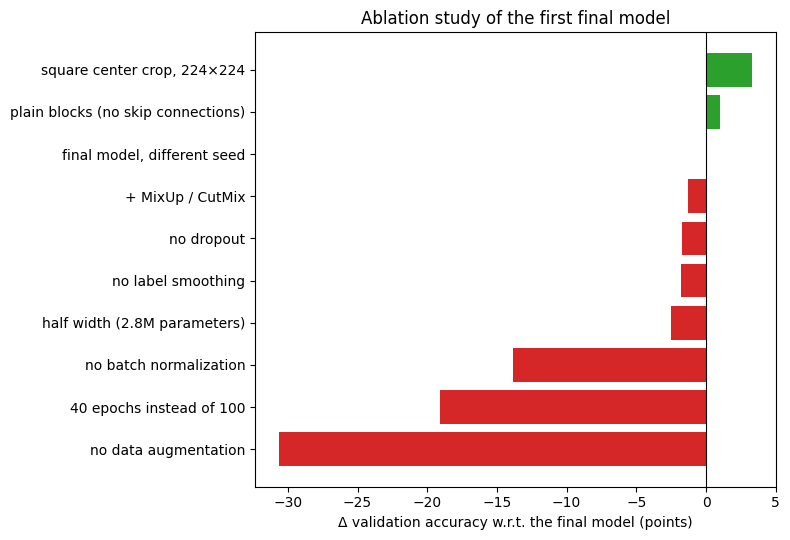

In [27]:
ablation_report(P1_FINAL_NAME, P1_ABLATION, P1_REUSED, title="Ablation study of the first final model")

> *Observations:* a second run of the final model with a different seed gives 59.1% vs 59.0% validation accuracy (1.3 points apart on the test set): differences below ≈1.5 points are within noise.
> - **Essential components**: data augmentation (−30.7 points: without it the network memorizes the training set, 100% training accuracy), the length of training (−19.1 with 40 epochs) and batch normalization (−13.9: without it even the training accuracy stops at 76%, so its main role here is to make optimization possible).
> - **Small contributions, at the level of noise**: half width (−2.5), label smoothing (−1.8), dropout (−1.7); adding MixUp/CutMix (−1.3) does not help.
> - **Skip connections are not needed** (+1.0, within noise): with batch normalization, a 16-layer plain network is trained just as well; residual connections become important for much deeper networks.
> - **The square center crop is better than the rectangular input (+3.3 points).** This contradicts our hypothesis, but the comparison mixes two factors: in crop mode the image is resized to a height of 256 px before cropping, in rect mode to 192 px, so the crop sees the aircraft at 1.33× higher resolution. It loses nose and tail, but it gains details on fuselage, engines and windows, which matter more in a fine-grained task. The next section separates the two factors.

### P1.8 Geometry or resolution?

`p1_rect256` uses the rectangular input at 256×384: the same scale as the center crop, but with the whole aircraft.
- if it beats the crop, keeping the whole aircraft *does* help and the first rectangular model was only too low-resolution;
- if it does not, what matters is the resolution on the central part of the aircraft.

The best of the three input geometries on the **validation** set becomes the final model of Part 1.

[p1_rect256] already completed (local): val acc 0.6160 | test acc 0.6052


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
rectangular 192×288 (first final model),11.203,100,90,0.990,0.590,0.584,36.124,Tesla T4,0.000,0.000
square center crop 224×224,11.203,100,97,0.976,0.623,0.618,7.956,NVIDIA L4,0.033,0.034
rectangular 256×384,11.203,100,94,0.984,0.616,0.605,15.494,NVIDIA L4,0.026,0.022


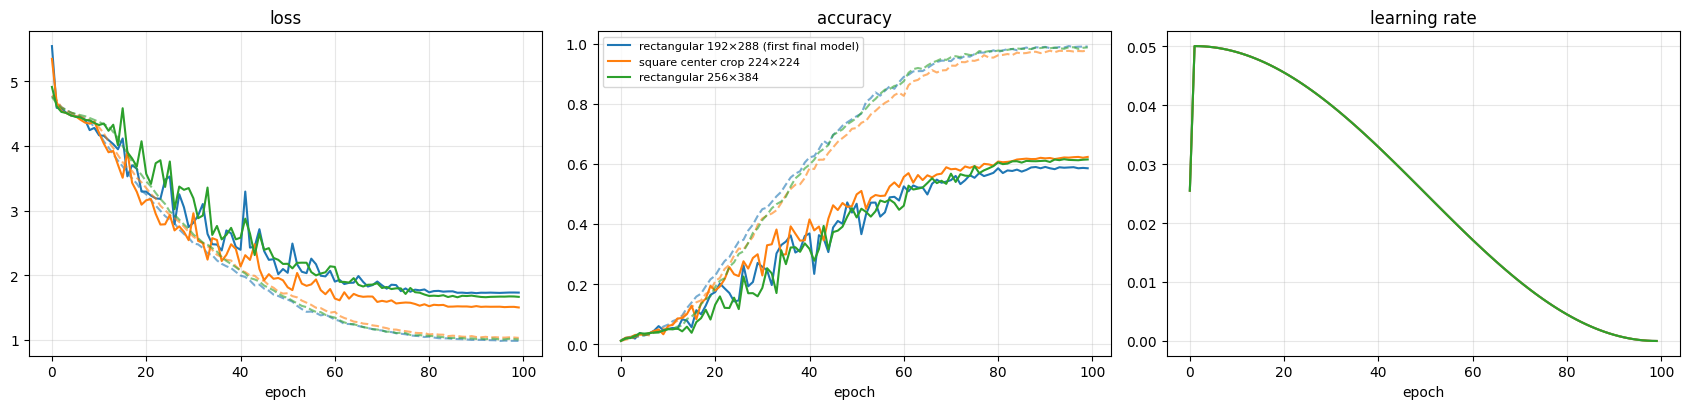

Final model of Part 1: p1_abl_crop (square center crop 224×224)


In [28]:
RUN_P1_GEOMETRY = True

P1_GEOMETRY = {  # run name: (description, config) — all identical except for the input geometry
    "p1_d2w2_reg_e100": ("rectangular 192×288 (first final model)", P1_FINAL),
    "p1_abl_crop":      ("square center crop 224×224",              P1_ABLATION["p1_abl_crop"][1]),
    "p1_rect256":       ("rectangular 256×384",                     dict(P1_FINAL, img_size=[256, 384])),
}
if RUN_P1_GEOMETRY:
    run_experiment("p1_rect256", build_aircraftnet, P1_GEOMETRY["p1_rect256"][1])

names = list(P1_GEOMETRY)
display(results_table(names, [d for d, _ in P1_GEOMETRY.values()], reference=names[0]))
plot_runs(names, [d for d, _ in P1_GEOMETRY.values()])

# Model selection on the validation accuracy only
P1_FINAL2_NAME = max((n for n in P1_GEOMETRY if is_done(n)), key=lambda n: _load(n)[2]["best_val_acc"])
P1_FINAL2 = P1_GEOMETRY[P1_FINAL2_NAME][1]
print(f"Final model of Part 1: {P1_FINAL2_NAME} ({P1_GEOMETRY[P1_FINAL2_NAME][0]})")

> *Observations:* at the same scale as the crop, the rectangular input (256×384, 61.6%) is 2.6 points better than at 192×288 (59.0%) and within noise of the square crop (62.3%). **The resolution, not the geometry, explains the gap found in P1.7**: keeping nose and tail brings no measurable benefit, while seeing the aircraft at a higher resolution does. On validation accuracy the square center crop is (marginally) the best option, and it is also about twice as fast (50k vs 98k input pixels): it becomes the final model of Part 1.

### P1.9 Final model and ablation study

The ablation study is repeated with respect to the final model selected in P1.8, with the same components as in P1.7
plus the width, the length of training and MixUp/CutMix, which are now re-trained with the final input geometry.
The other two input geometries of P1.8 differ from the final model in one component only and are reused.

In [29]:
RUN_P1_ABLATION2 = True

F2 = P1_FINAL2
P1_ABLATION2 = {  # ordered by expected informativeness
    "p1_abl2_seed1":     ("final model, different seed",        dict(F2, seed=SEED + 1)),
    "p1_abl2_noaug":     ("no data augmentation",               dict(F2, aug="none")),
    "p1_abl2_plain":     ("plain blocks (no skip connections)", dict(F2, block="plain")),
    "p1_abl2_nobn":      ("no batch normalization",             dict(F2, bn=False)),
    "p1_abl2_nols":      ("no label smoothing",                 dict(F2, label_smoothing=0.0)),
    "p1_abl2_nodrop":    ("no dropout",                         dict(F2, dropout=0.0)),
    "p1_abl2_halfwidth": ("half width (2.8M parameters)",       dict(F2, widths=[32, 64, 128, 256])),
    "p1_abl2_e40":       ("40 epochs instead of 100",           dict(F2, epochs=40)),
    "p1_abl2_mix":       ("+ MixUp / CutMix",                   dict(F2, mixup_alpha=0.2, cutmix_alpha=1.0)),
}
P1_REUSED2 = {n: d for n, (d, _) in P1_GEOMETRY.items() if n != P1_FINAL2_NAME}

if RUN_P1_ABLATION2:
    for run_name, (_, cfg) in P1_ABLATION2.items():
        run_experiment(run_name, build_aircraftnet, cfg)

[p1_abl2_seed1] already completed (local): val acc 0.6268 | test acc 0.6160
[p1_abl2_noaug] already completed (local): val acc 0.3432 | test acc 0.3465
[p1_abl2_plain] already completed (local): val acc 0.6217 | test acc 0.6301
[p1_abl2_nobn] already completed (local): val acc 0.4752 | test acc 0.4656
[p1_abl2_nols] already completed (local): val acc 0.6190 | test acc 0.6199
[p1_abl2_nodrop] already completed (local): val acc 0.6190 | test acc 0.6031
[p1_abl2_halfwidth] already completed (local): val acc 0.5998 | test acc 0.5980
[p1_abl2_e40] already completed (local): val acc 0.4362 | test acc 0.4419
[p1_abl2_mix] already completed (local): val acc 0.6061 | test acc 0.5890


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
final model,11.203,100,97,0.976,0.623,0.618,7.956,NVIDIA L4,0.000,0.000
"final model, different seed",11.203,100,97,0.977,0.627,0.616,7.834,NVIDIA L4,0.003,-0.002
no data augmentation,11.203,100,97,1.000,0.343,0.347,7.380,NVIDIA L4,-0.280,-0.271
plain blocks (no skip connections),11.027,100,95,0.959,0.622,0.630,7.074,NVIDIA L4,-0.002,0.012
no batch normalization,11.198,100,97,0.671,0.475,0.466,7.253,NVIDIA L4,-0.148,-0.152
no label smoothing,11.203,100,96,0.961,0.619,0.620,7.820,NVIDIA L4,-0.005,0.002
no dropout,11.203,100,92,0.989,0.619,0.603,7.816,NVIDIA L4,-0.005,-0.015
half width (2.8M parameters),2.822,100,96,0.913,0.600,0.598,6.112,NVIDIA L4,-0.024,-0.020
40 epochs instead of 100,11.203,40,38,0.543,0.436,0.442,3.201,NVIDIA L4,-0.187,-0.176


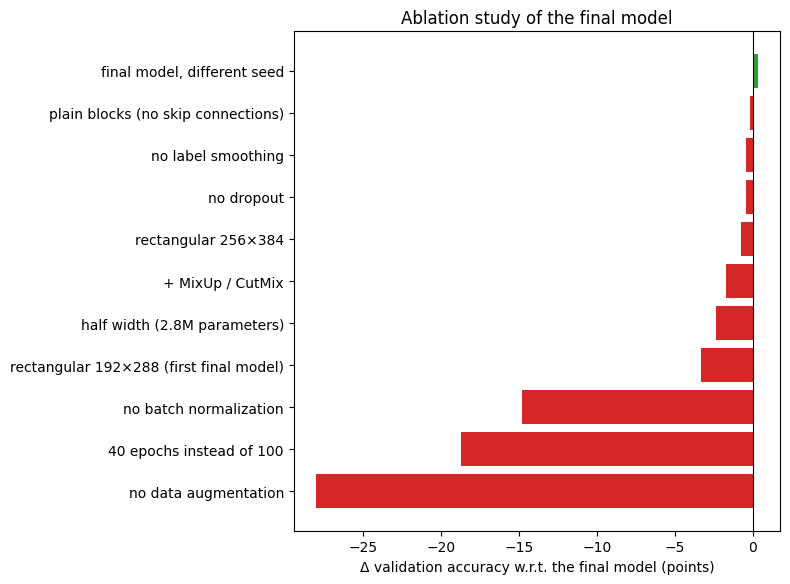

In [30]:
ablation_report(P1_FINAL2_NAME, P1_ABLATION2, P1_REUSED2, title="Ablation study of the final model")

> *Observations:* the final model reaches **62.3% validation and 61.8% test accuracy**; the run with a different seed (62.7% / 61.6%) confirms that differences below ≈1 point are noise.
> - **Essential components**: data augmentation (−28.0 points: without it the network memorizes the training set), training length (−18.7 with 40 epochs) and batch normalization (−14.8: without it even the training accuracy stops at 67%, so its role is mainly to make optimization possible).
> - **Moderate effect**: halving the width costs 2.4 points (4× fewer parameters), while adding MixUp/CutMix hurts (−1.7), because such strong regularization would need a longer schedule (training accuracy stays at 71%).
> - **No measurable effect**: skip connections (−0.2), label smoothing (−0.5), dropout (−0.5) and the whole-aircraft rectangular input (−0.8). With strong augmentation and a long schedule, augmentation is the dominant regularizer and the others become redundant; similarly, a 16-layer network with batch normalization is trained just as well without skip connections, which pay off only in much deeper networks. The final model could therefore be simplified without loss of accuracy.
> - The ranking of the components is the same as in the ablation of the first final model (P1.7), which makes these conclusions robust.

## Part 2: fine-tune an existing network

Your goal is to fine-tune a pretrained ResNet-18 model on `FGVCAircraft`. Use the implementation provided by PyTorch, i.e. the opposite of part 1. Specifically, use the PyTorch ResNet-18 model pretrained on ImageNet-1K (V1). Divide your fine-tuning into two parts:

2A. First, fine-tune the ResNet-18 with the same training hyperparameters you used for your best model in part 1.

2B. Then, tweak the training hyperparameters to increase the accuracy on the test split. Justify your choices by analyzing the training plots and/or citing sources that guided you in your decisions — papers, blog posts, YouTube videos, or whatever else you may find useful. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~70%.

### 2A. Fine-tuning with the hyperparameters of Part 1

The pretrained ResNet-18 (ImageNet-1K V1 weights) keeps all its layers; only the final fully connected layer is replaced
by a new one with 100 outputs. The model is trained with **the same training hyperparameters of the final model of Part 1**
(input 224×224 center crop with strong augmentation, SGD with Nesterov momentum, LR 0.05, weight decay 5·10⁻⁴,
cosine schedule with 2 warm-up epochs, label smoothing 0.1, batch size 64, 100 epochs). The dropout (0.3) before the
classifier is also kept, as part of the same training recipe; the architectural choices of Part 1 (widths, depths,
blocks) obviously do not apply.

Inputs were normalized with the ImageNet statistics since Part 1, so the pretrained network receives inputs from the
distribution it was trained on without any change to the pipeline.

{
 "seed": 42,
 "img_size": 224,
 "resize_mode": "crop",
 "aug": "strong",
 "rrc_scale": [
  0.35,
  1.0
 ],
 "batch_size": 64,
 "epochs": 100,
 "optimizer": "sgd",
 "lr": 0.05,
 "wd": 0.0005,
 "scheduler": "cosine",
 "warmup_epochs": 2,
 "label_smoothing": 0.1,
 "mixup_alpha": 0.0,
 "cutmix_alpha": 0.0,
 "dropout": 0.3,
 "model": "resnet18_imagenet1k_v1"
}
[p2a_resnet18] already completed (local): val acc 0.7201 | test acc 0.7246


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu
run,,,,,,,,
Part 1 final model (from scratch),11.203,100,97,0.976,0.623,0.618,7.956,NVIDIA L4
"2A: ResNet-18 pretrained, Part 1 hyperparameters",11.228,100,85,0.997,0.720,0.725,8.205,NVIDIA L4


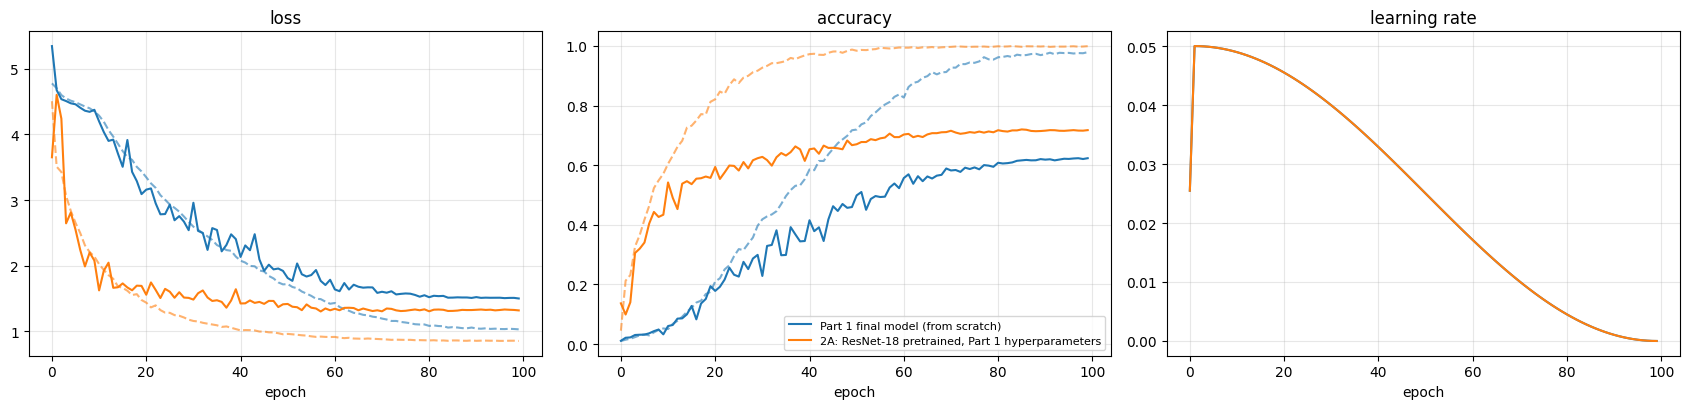

In [31]:
from torchvision.models import resnet18, ResNet18_Weights


def build_resnet18(cfg):
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Sequential(nn.Dropout(cfg.get("dropout", 0.0)), nn.Linear(model.fc.in_features, num_classes))
    return model


TRAINING_KEYS = ["seed", "img_size", "resize_mode", "aug", "rrc_scale", "batch_size", "epochs", "optimizer", "lr", "wd",
                 "scheduler", "warmup_epochs", "label_smoothing", "mixup_alpha", "cutmix_alpha", "dropout"]
P2A = dict({k: P1_FINAL2[k] for k in TRAINING_KEYS}, model="resnet18_imagenet1k_v1")
print(json.dumps(P2A, indent=1))

RUN_P2A = True
if RUN_P2A:
    run_experiment("p2a_resnet18", build_resnet18, P2A)

names = [P1_FINAL2_NAME, "p2a_resnet18"]
labels = ["Part 1 final model (from scratch)", "2A: ResNet-18 pretrained, Part 1 hyperparameters"]
display(results_table(names, labels))
plot_runs(names, labels)

> *Observations:*
> - **Pretraining is worth ≈10 points with the very same recipe**: 72.0% validation / 72.5% test accuracy, vs 62.3% / 61.8% from scratch — already above the ≈70% target.
> - **Much faster convergence**: the pretrained network reaches 60% validation accuracy around epoch 20 (the network trained from scratch needs ≈70 epochs) and fits the training set completely (≈100%) by epoch 50.
> - **The recipe is not tuned for fine-tuning**, and the plots show where:
>   1. in the first epochs, while the learning rate warms up to 0.05, the validation loss *increases* (from 3.7 to 4.6) and the validation accuracy drops: the large updates partially destroy the pretrained features, which the network then has to learn again;
>   2. validation accuracy plateaus from epoch ≈60 while the training accuracy is ≈100%: the second half of the schedule brings almost nothing, so 100 epochs are more than needed.

### 2B. Tuning the hyperparameters for fine-tuning

The observations on 2A suggest three directions, explored one at a time and selected on the validation accuracy:

1. **Shorter schedule** — validation accuracy plateaus from epoch ≈60, so we first check that 50 epochs lose nothing;
   this halves the cost of every following experiment.
2. **Smaller learning rate for the pretrained layers** — the loss spike at the beginning shows that LR 0.05 damages the
   pretrained features. Pretrained layers already encode useful features and should only be adapted gently, while the new
   classifier starts from random weights and needs a larger LR: this is the idea of *discriminative fine-tuning*
   (Howard & Ruder, *Universal Language Model Fine-tuning for Text Classification*, ACL 2018), also used in Lab 5.
   We compare a globally smaller LR (0.01) with a 10× smaller LR on the backbone only (0.005 backbone, 0.05 classifier).
   The choice of the fine-tuning learning rate is studied in depth by Li et al., *Rethinking the Hyperparameters for
   Fine-tuning*, ICLR 2020.
3. **Higher input resolution** (next step) — Part 1 showed that resolution is what matters most on this dataset
   (Section P1.8), and fine-grained recognition methods commonly use 448×448 inputs.

,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
"2A (100 epochs, LR 0.05)",11.228,100,85,0.997,0.720,0.725,8.205,NVIDIA L4,0.000,0.000
50 epochs,11.228,50,35,0.984,0.708,0.710,17.085,Tesla T4,-0.012,-0.014
"50 epochs, LR 0.01",11.228,50,39,0.989,0.693,0.701,17.774,Tesla T4,-0.027,-0.023
"50 epochs, LR 0.05 classifier / 0.005 backbone",11.228,50,41,0.996,0.662,0.672,17.353,Tesla T4,-0.058,-0.052


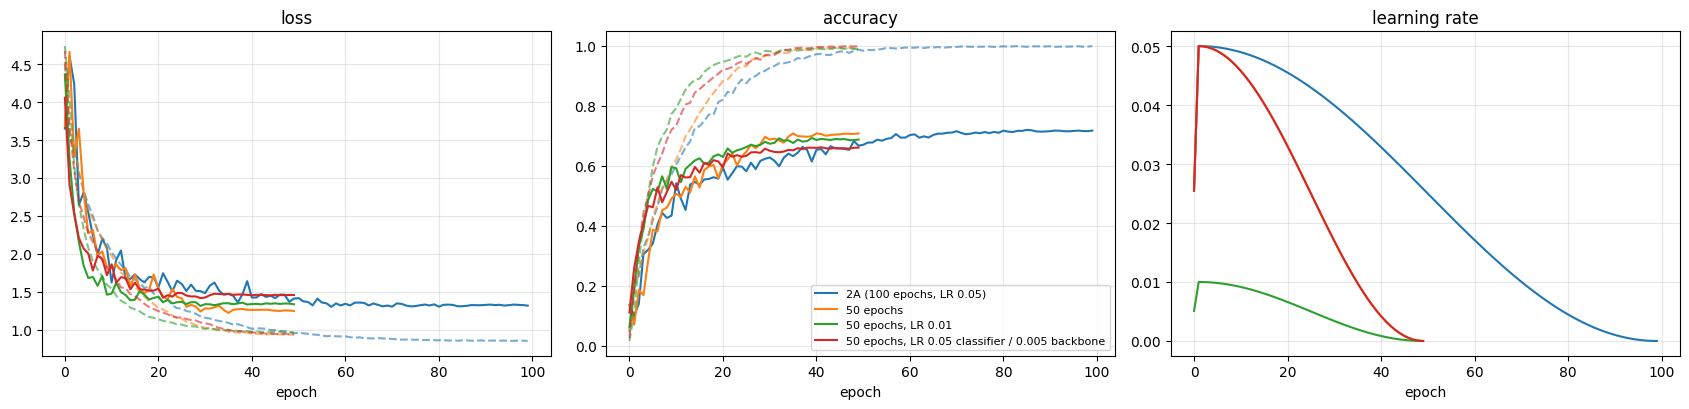

In [32]:
def resnet_param_groups(model, cfg):
    """Classifier (fc) with the base LR, pretrained backbone with LR × backbone_lr_mult (discriminative fine-tuning).
    The classifier group comes first, so the plotted LR is the one of the classifier, as in the other runs."""
    head = list(model.fc.parameters())
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    return [{"params": head, "lr": cfg["lr"]},
            {"params": backbone, "lr": cfg["lr"] * cfg.get("backbone_lr_mult", 1.0)}]


RUN_P2B_1 = False

P2B_1 = {
    "p2b_e50":        ("50 epochs",                                     dict(P2A, epochs=50)),
    "p2b_e50_lr001":  ("50 epochs, LR 0.01",                            dict(P2A, epochs=50, lr=0.01)),
    "p2b_e50_difflr": ("50 epochs, LR 0.05 classifier / 0.005 backbone", dict(P2A, epochs=50, backbone_lr_mult=0.1)),
}
if RUN_P2B_1:
    for run_name, (_, cfg) in P2B_1.items():
        run_experiment(run_name, build_resnet18, cfg, build_params=resnet_param_groups)

names = ["p2a_resnet18"] + list(P2B_1)
labels = ["2A (100 epochs, LR 0.05)"] + [d for d, _ in P2B_1.values()]
display(results_table(names, labels, reference=names[0]))
plot_runs(names, labels)

> *Observations:*
> - **50 epochs instead of 100** cost little: 70.8% vs 72.0% validation accuracy (−1.2 points), and the curves of 2A are almost flat in their second half. We use 50 epochs for the exploration, which halves the cost of the following experiments, and check the choice again on the final configuration.
> - **Smaller learning rates are worse, not better.** LR 0.01 everywhere gives 69.3% (−1.5 w.r.t. 50 epochs at 0.05); a 10× smaller LR on the backbone only (discriminative fine-tuning) gives 66.2% (−4.7), the worst result of this section. Both runs fit the training set as well as the others (the dashed curves reach ≈100%), but their validation loss stays higher: the difference is in how well they generalize, not in how well they optimize.
> - Our hypothesis is therefore wrong: the loss spike of the first epochs is quickly recovered and does not hurt the final accuracy. This agrees with Li et al. (2020): the more the target task differs from the source one, the more the best fine-tuning hyperparameters resemble those of training from scratch, with larger learning rates. Aircraft variants are far from the ImageNet classes, so the pretrained features have to change substantially, not just be slightly adjusted.

#### A larger learning rate

Since smaller learning rates hurt, we test the opposite direction: LR 0.1 on the whole network (warm-up and cosine schedule
unchanged), still at 224×224, where a 50-epoch run costs only a few minutes.

[p2b_e50_lr01] already completed (local): val acc 0.7072 | test acc 0.7054


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
"50 epochs, LR 0.05",11.228,50,35,0.984,0.708,0.710,17.085,Tesla T4,0.000,0.000
"50 epochs, LR 0.1",11.228,50,44,0.985,0.707,0.705,4.150,NVIDIA L4,-0.001,-0.005


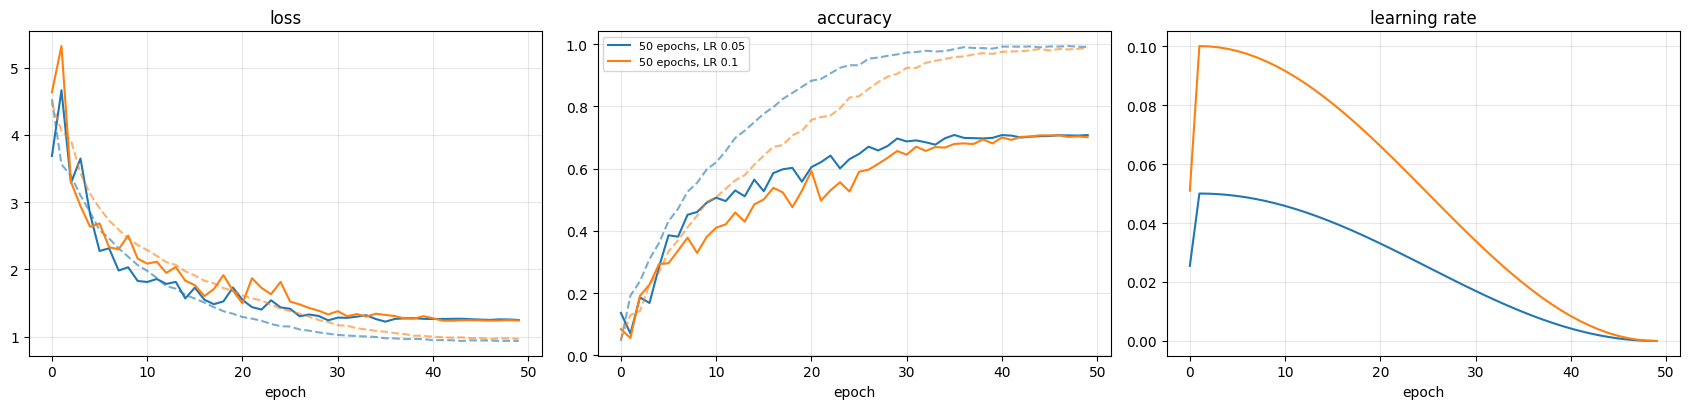

In [33]:
RUN_P2B_LR = True

P2B_LR = {
    "p2b_e50_lr01": ("50 epochs, LR 0.1", dict(P2A, epochs=50, lr=0.1)),
}
if RUN_P2B_LR:
    for run_name, (_, cfg) in P2B_LR.items():
        run_experiment(run_name, build_resnet18, cfg, build_params=resnet_param_groups)

names = ["p2b_e50"] + list(P2B_LR)
labels = ["50 epochs, LR 0.05"] + [d for d, _ in P2B_LR.values()]
display(results_table(names, labels, reference="p2b_e50"))
plot_runs(names, labels)

> *Observations:* LR 0.1 is not better: 70.7% validation accuracy (−0.1 points) and 70.5% test accuracy (−0.5), within the run-to-run noise. The curves show that it learns more slowly — training and validation accuracy stay below those of LR 0.05 for most of the training, and the best epoch is the 44th — and catches up only at the end, when the cosine schedule has brought the learning rate down. Over all the runs at 224×224 (66.2% with 0.005 on the backbone, 69.3% with 0.01, 70.8% with 0.05, 70.7% with 0.1) the accuracy grows with the learning rate up to 0.05 and then stops improving: the best learning rate is around 0.05, the value found in Part 1, which we keep.

#### Input resolution

Part 1 showed that, on this dataset, what matters most is the resolution at which the aircraft is seen (Section P1.8), and
fine-grained recognition methods commonly use 448×448 inputs. Since ImageNet features are learned at 224×224, we also test
an intermediate resolution (336×336) to see whether the gain grows steadily with the resolution. Everything else is the
50-epoch configuration (`p2b_e50`), so that the resolution is the only change; images are taken from caches with a larger
short side (384 and 512 px), so that the crops are never upsampled (these caches are stored as JPEG at quality 95, Section 1.2: a
negligible compression compared to the change of resolution, since the original images are JPEGs as well). The cost of an epoch grows roughly with the number of
pixels (×2.25 at 336, ×4 at 448).

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 218MB/s]


[p2b_e50_336] 11.23M parameters (11.23M trainable) on NVIDIA A100-SXM4-80GB


train, 384 px:   0%|          | 0/3334 [00:00<?, ?it/s]

[train, 384 px] 3334 images processed in 13s


val, 384 px:   0%|          | 0/3333 [00:00<?, ?it/s]

... (3 outputs left out)

[test, 384 px] 3333 images processed in 13s
[p2b_e50_336] best epoch 42 | val acc 0.7558 | test acc 0.7744
[p2b_e50_448] 11.23M parameters (11.23M trainable) on NVIDIA A100-SXM4-80GB
[train, 512 px] loaded 3334 images from cache in 15s
[val, 512 px] loaded 3333 images from cache in 12s


francesco_p2b_e50_448:   0%|          | 0/50 [00:00<?, ?it/s]

[test, 512 px] loaded 3333 images from cache in 10s
[p2b_e50_448] best epoch 41 | val acc 0.8020 | test acc 0.8080


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
"50 epochs, 224×224",11.228,50,35,0.984,0.708,0.710,17.085,Tesla T4,0.000,0.000
"50 epochs, 336×336",11.228,50,42,0.995,0.756,0.774,7.354,NVIDIA A100-SXM4-80GB,0.047,0.064
"50 epochs, 448×448",11.228,50,41,0.998,0.802,0.808,12.716,NVIDIA A100-SXM4-80GB,0.094,0.098


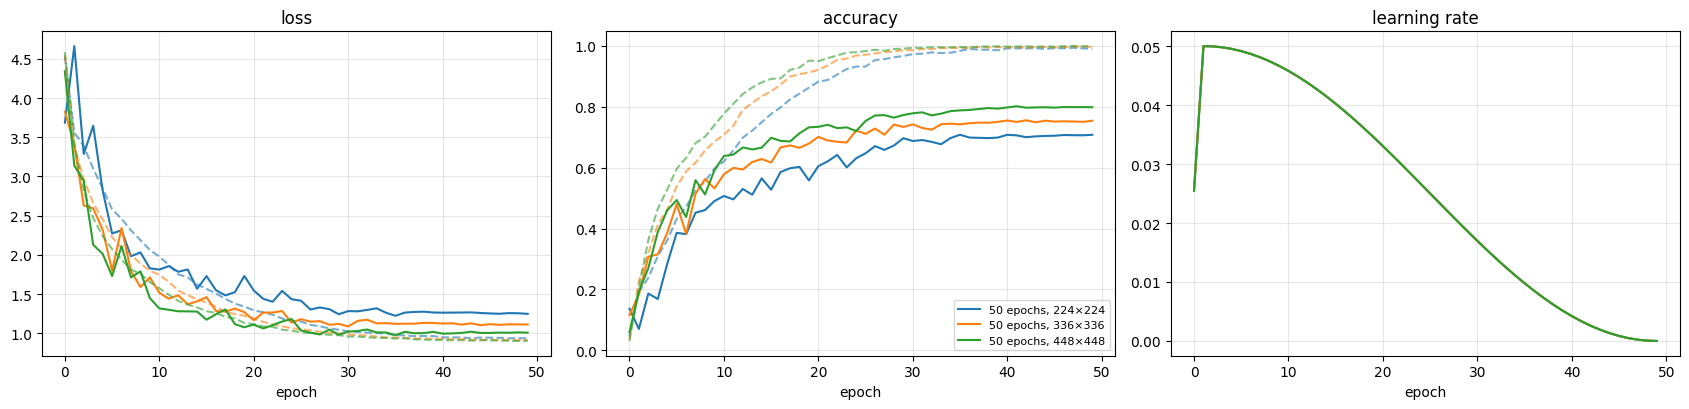

In [34]:
RUN_P2B_RES = True

P2B_RES = {
    "p2b_e50_336": ("50 epochs, 336×336", dict(P2B_1["p2b_e50"][1], img_size=336, short_side=384)),
    "p2b_e50_448": ("50 epochs, 448×448", dict(P2B_1["p2b_e50"][1], img_size=448, short_side=512)),
}
if RUN_P2B_RES:
    for run_name, (_, cfg) in P2B_RES.items():
        run_experiment(run_name, build_resnet18, cfg, build_params=resnet_param_groups)

names = ["p2b_e50"] + list(P2B_RES)
labels = ["50 epochs, 224×224"] + [d for d, _ in P2B_RES.values()]
display(results_table(names, labels, reference="p2b_e50"))
plot_runs(names, labels)

> *Observations:*
> - **The input resolution is by far the most effective change**: going from 224 to 336 to 448 px, validation accuracy grows from 70.8% to 75.6% to 80.2% (test: 71.0% → 77.4% → 80.8%), with no sign of saturation yet (+4.8 and +4.6 points at each step). As in Part 1 (P1.8), seeing the aircraft at a higher resolution makes visible the small details that separate the variants (windows, doors, engines, length of the fuselage).
> - The higher-resolution networks are better at almost **every epoch** (from epoch ≈10 on), not only at the end, and their validation loss settles at a lower value (≈1.0 at 448, ≈1.1 at 336, ≈1.25 at 224).
> - **Cost**: the time per epoch grows roughly with the number of pixels: on the same GPU (A100), 50 epochs take 7 minutes at 336 and 13 minutes at 448. The runs of this notebook were trained on different GPUs (T4, L4, A100), so their training times are not directly comparable.
> - **What does not change**: all networks fit the training set almost perfectly (≈100% from epoch ≈35) and the validation accuracy is flat in the last ≈10 epochs. The loss spike of the first epochs, when the warm-up brings the learning rate to 0.05, is still there (most visible at 224), but, as seen above, it does not hurt the final accuracy.

#### 50 or 100 epochs at 448×448?

The choice of 50 epochs was made at 224×224, where it cost 1.2 points with respect to 100 epochs. We check whether it
still holds at 448×448: everything else is identical to `p2b_e50_448`, only the number of epochs changes.

[p2b_e100_448] already completed (local): val acc 0.8050 | test acc 0.8182


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
"50 epochs, 448×448",11.228,50,41,0.998,0.802,0.808,12.716,NVIDIA A100-SXM4-80GB,0.000,0.000
"100 epochs, 448×448",11.228,100,88,1.000,0.805,0.818,32.499,NVIDIA L4,0.003,0.010


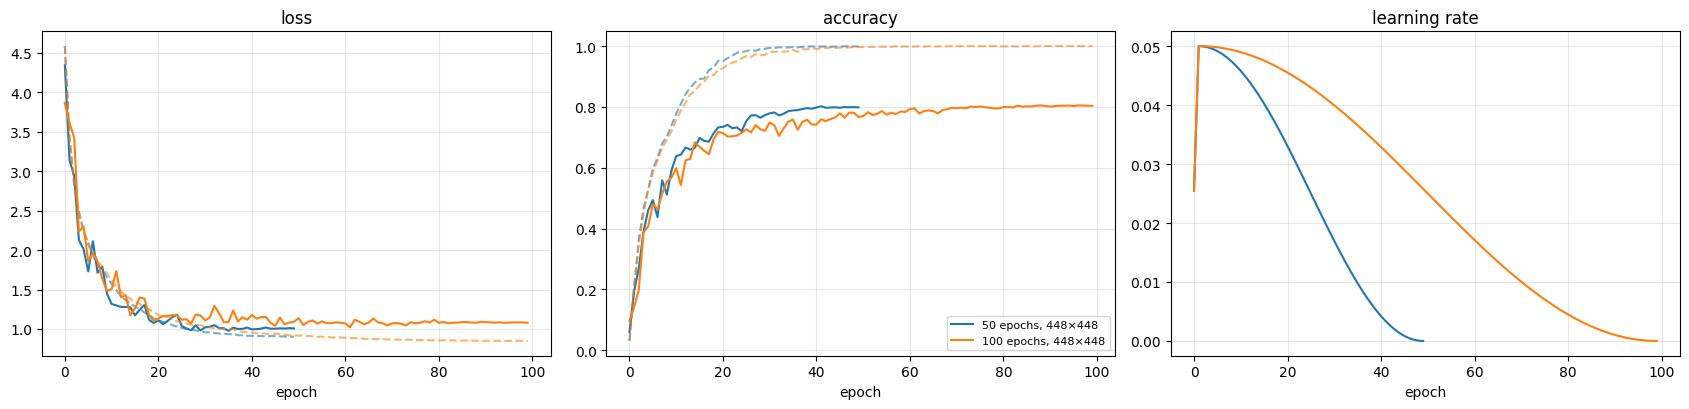

In [35]:
RUN_P2B_E100 = True

P2B_E100 = {
    "p2b_e100_448": ("100 epochs, 448×448", dict(P2B_RES["p2b_e50_448"][1], epochs=100)),
}
if RUN_P2B_E100:
    for run_name, (_, cfg) in P2B_E100.items():
        run_experiment(run_name, build_resnet18, cfg, build_params=resnet_param_groups)

names = ["p2b_e50_448"] + list(P2B_E100)
labels = ["50 epochs, 448×448"] + [d for d, _ in P2B_E100.values()]
display(results_table(names, labels, reference="p2b_e50_448"))
plot_runs(names, labels)

> *Observations:* with 100 epochs the 448×448 network reaches **80.5% validation / 81.8% test accuracy**, only +0.3 / +1.0 points w.r.t. 50 epochs (80.2% / 80.8%): unlike at 224×224 (+1.2), at high resolution doubling the schedule brings no significant gain, and the two runs are equivalent within the run-to-run noise. Training accuracy reaches 100% around epoch 50, and validation accuracy barely moves afterwards (the validation loss stays flat at ≈1.08). Following our rule, the final model of 2B is the one with the best validation accuracy, i.e. the 100-epoch run; the 50-epoch run would be an equally valid choice at half the training cost.

### 2B. Final model

The final configuration of 2B is the one with the best validation accuracy among the 448×448 runs (50 or 100 epochs):
the hyperparameters of Part 1 (SGD, LR 0.05, cosine schedule with warm-up, the same augmentation and regularization)
with a 448×448 input instead of 224×224.

In [36]:
P2B_CANDIDATES = {"p2b_e50_448": "50 epochs, 448×448", "p2b_e100_448": "100 epochs, 448×448"}
P2B_FINAL_NAME = max((n for n in P2B_CANDIDATES if is_done(n)), key=lambda n: _load(n)[2]["best_val_acc"])

names = [P1_FINAL2_NAME, "p2a_resnet18", P2B_FINAL_NAME]
labels = ["Part 1: our network (224×224)", "2A: ResNet-18, hyperparameters of Part 1",
          f"2B: ResNet-18, {P2B_CANDIDATES[P2B_FINAL_NAME]}"]
display(results_table(names, labels, reference=P1_FINAL2_NAME))

,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
Part 1: our network (224×224),11.203,100,97,0.976,0.623,0.618,7.956,NVIDIA L4,0.000,0.000
"2A: ResNet-18, hyperparameters of Part 1",11.228,100,85,0.997,0.720,0.725,8.205,NVIDIA L4,0.097,0.107
"2B: ResNet-18, 100 epochs, 448×448",11.228,100,88,1.000,0.805,0.818,32.499,NVIDIA L4,0.182,0.200


## Conclusions

- **Part 1.** A ResNet-like network trained from scratch reaches 61.8% test accuracy on 100 fine-grained classes with ≈33
  training images per class. The ablation study shows that data augmentation, BatchNorm, a long enough training and the
  width of the network are what make this possible, while the skip connections, label smoothing and dropout have no
  measurable effect in our setting.
- **2A.** The same recipe applied to an ImageNet-pretrained ResNet-18 of the same size gives 72.5% (+10.7 points): with so
  few images per class, the features learned on 1.2M images are worth more than any design choice we made.
- **2B.** Tuning the fine-tuning brings the test accuracy to 81.8% (+9.3 over 2A). The decisive change is the input
  resolution (448×448 instead of 224×224), which is also what mattered most in Part 1: fine-grained classes differ in
  small details that 224×224 inputs do not preserve; at high resolution a longer schedule (100 epochs) brings no
  significant further gain. Smaller learning rates for the pretrained layers, the usual fine-tuning recipe, made things worse: aircraft
  variants are far from the ImageNet classes, and the pretrained features must be substantially adapted (Li et al., 2020).
- In every experiment the models were selected on the validation split only; the test split was evaluated once per run,
  on the checkpoint chosen on the validation split, and only reported.

## Appendix: publishing the runs

Run at the end of a working session to update the zip file of the published runs (Section 2.5).

In [37]:
PUBLISH = False

if PUBLISH:
    publish_runs(with_checkpoints=[P1_FINAL2_NAME, "p2a_resnet18", P2B_FINAL_NAME])